# 🎓 Customer Churn Prediction — Multi-Algorithm Classification Showdown
**Red & White Skill Education · Practical Exam · Supervised Learning (Set B)**

Dataset: [IBM Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (7,043 customers, 21 columns) · Target: `Churn`

Models: **KNN · Gaussian Naive Bayes · SVM (RBF) · Decision Tree** — with `SMOTE` / `class_weight` for imbalance.

# 🧠 Step 1: Problem Framing & Theory Notes

**1. What is Customer Churn? Why predict it? (CAC vs CLV)**
- Churn = a paying subscriber leaving the service (e.g. porting out from Jio to Airtel).
- Acquiring a new customer (**CAC**) is typically 5–7x costlier than retaining an existing one; a churner also takes away all their future **CLV** (customer lifetime value).
- If we know *who* is about to leave, the retention team can target them with offers/calls *before* they go, so CAC is saved and CLV is protected.

**2. Confusion Matrix**
- **TP** – predicted churn, actually churned (correctly flagged leaver). **TN** – predicted stay, actually stayed.
- **FP** – predicted churn, but customer would have stayed. **FN** – predicted stay, but customer actually left.
- **Cost of FN (high):** we lose the customer plus their whole CLV and must spend CAC to replace them. **Cost of FP (lower):** we waste a discount/call on a loyal customer — a small, bounded cost.

**3. Class Imbalance & SMOTE**
- Class imbalance = one class has far fewer samples than the other, so a model can get high accuracy just by predicting the majority class.
- Telco Churn **is imbalanced** (~26.5% churn vs ~73.5% retained — verified in EDA below).
- **SMOTE** creates *synthetic* minority samples by interpolating between a minority point and its k nearest minority neighbours; it is applied **only on the training set** to avoid leakage.

**4. The four algorithms**
- **KNN** – no real training; classifies a customer by majority vote of its *k* closest customers (distance-based, needs scaling).
- **Gaussian Naive Bayes** – applies Bayes' theorem with the "naive" assumption that features are independent given the class; each feature is modelled with a Gaussian per class. Very fast.
- **SVM (RBF)** – finds the maximum-margin boundary between classes; the RBF kernel lets the boundary be non-linear. `C` controls margin-vs-misclassification trade-off.
- **Decision Tree** – repeatedly splits data on the feature/threshold that most reduces impurity (Gini), giving human-readable if-else rules.

**5. Precision vs Recall**
- Recall is primary when missing a churner is expensive (our default case).
- **Precision** becomes primary when the retention action is *expensive or capacity-limited* — e.g. a costly ₹500 cashback or a human call (team can only call ~500/day): flagging 2,000 mostly-wrong customers wastes budget and agent time.

# 📂 Step 2: Dataset Loading & Exploratory Data Analysis

In [4]:
import warnings, time, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import churn_features as cf

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("images", exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 2.1 Load & Inspect

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape, "\n")
df.info()

Shape: (7043, 21) 

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

In [3]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


**`TotalCharges` is an `object` column** — let's find out why.

In [5]:
ws = df[df["TotalCharges"].str.strip() == ""]
print("Rows where TotalCharges is blank/whitespace:", len(ws))
ws[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows where TotalCharges is blank/whitespace: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All blank rows have `tenure = 0` — these are brand-new customers who have not been billed yet, so `TotalCharges` is genuinely missing (stored as `" "`). We coerce to numeric (blanks → `NaN`) and, as instructed, fill with the **median** (done in Step 3.1; here we only convert).

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].dtype, "| nulls:", df["TotalCharges"].isna().sum())

vc = df["Churn"].value_counts()
print("\nClass balance:\n", vc, "\n", (df["Churn"].value_counts(normalize=True)*100).round(2).astype(str) + " %")

float64 | nulls: 11

Class balance:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64 
 Churn
No     73.46 %
Yes    26.54 %
Name: proportion, dtype: str


**Class balance:** 1,869 of 7,043 customers churned = **26.54%** vs 73.46% retained (≈ 2.8 : 1). So the data is **moderately imbalanced**; accuracy alone is misleading because a model that always says 'No Churn' would already score ~73.5%. We therefore focus on Recall / F1 of the Churn class.

## 2.2 Univariate Analysis

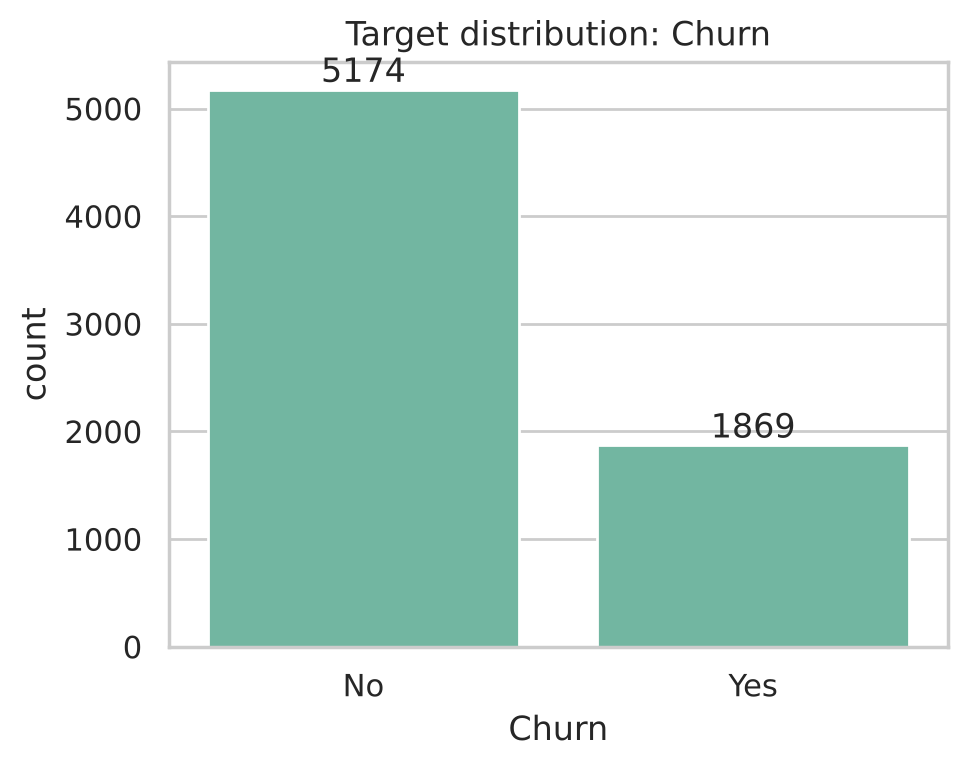

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target distribution: Churn")
savefig("01_churn_countplot")

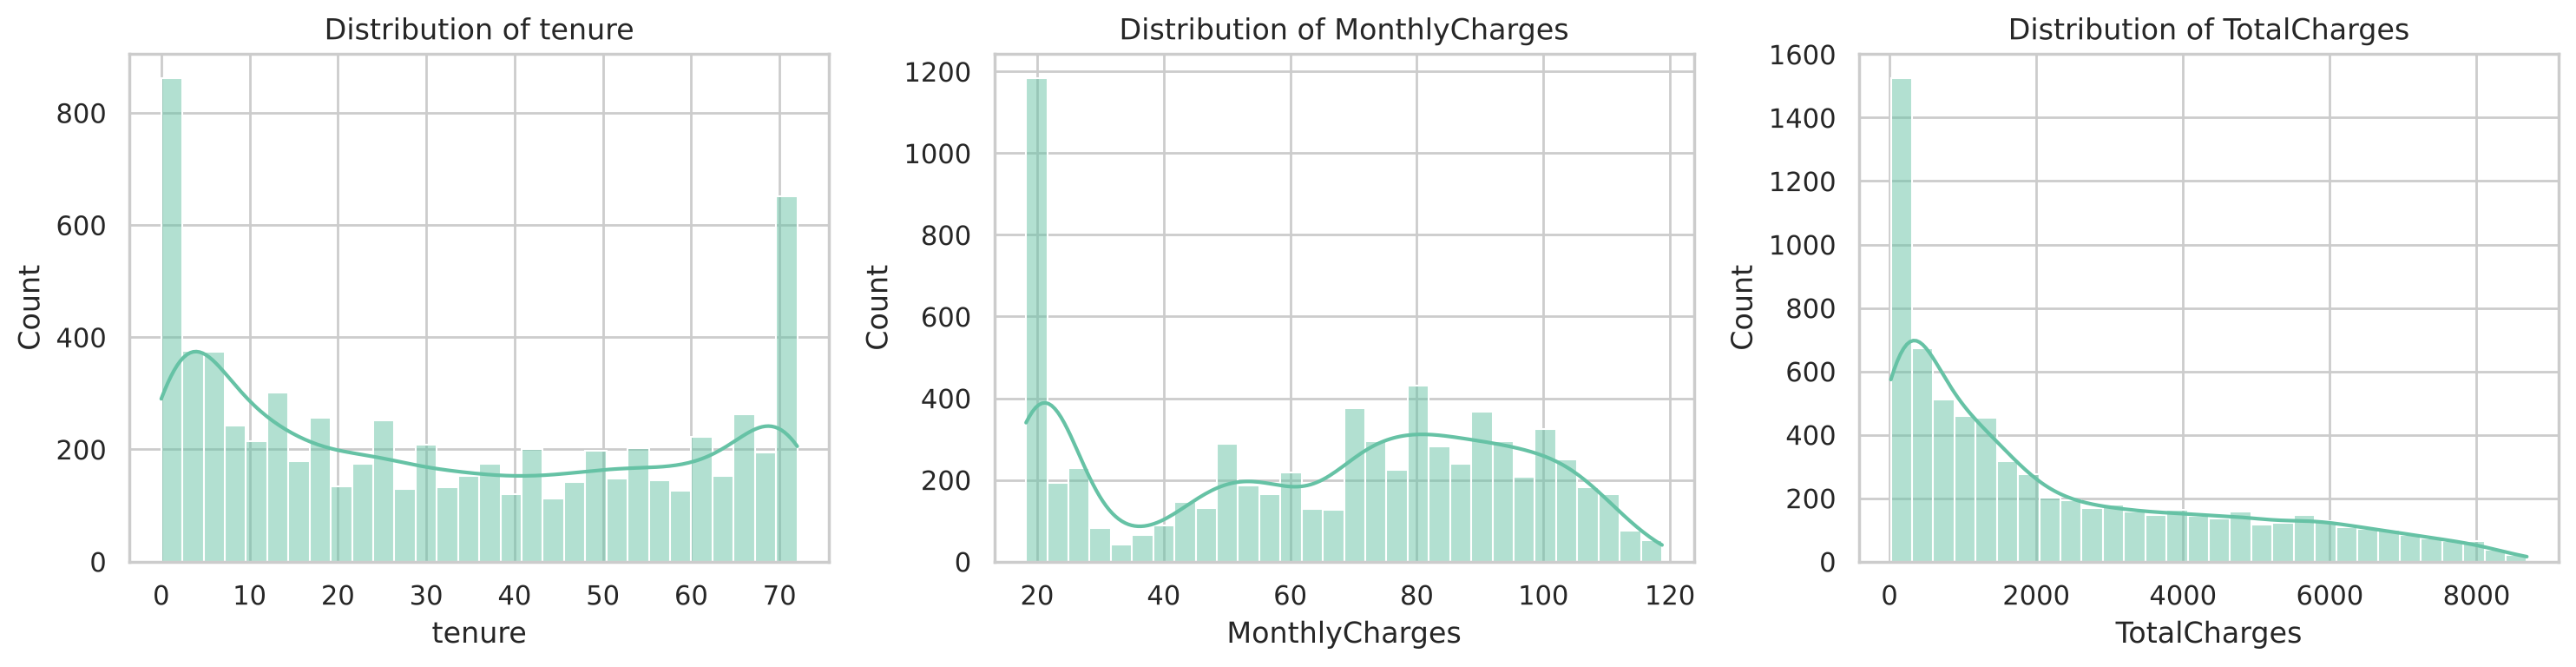

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
savefig("02_histograms")

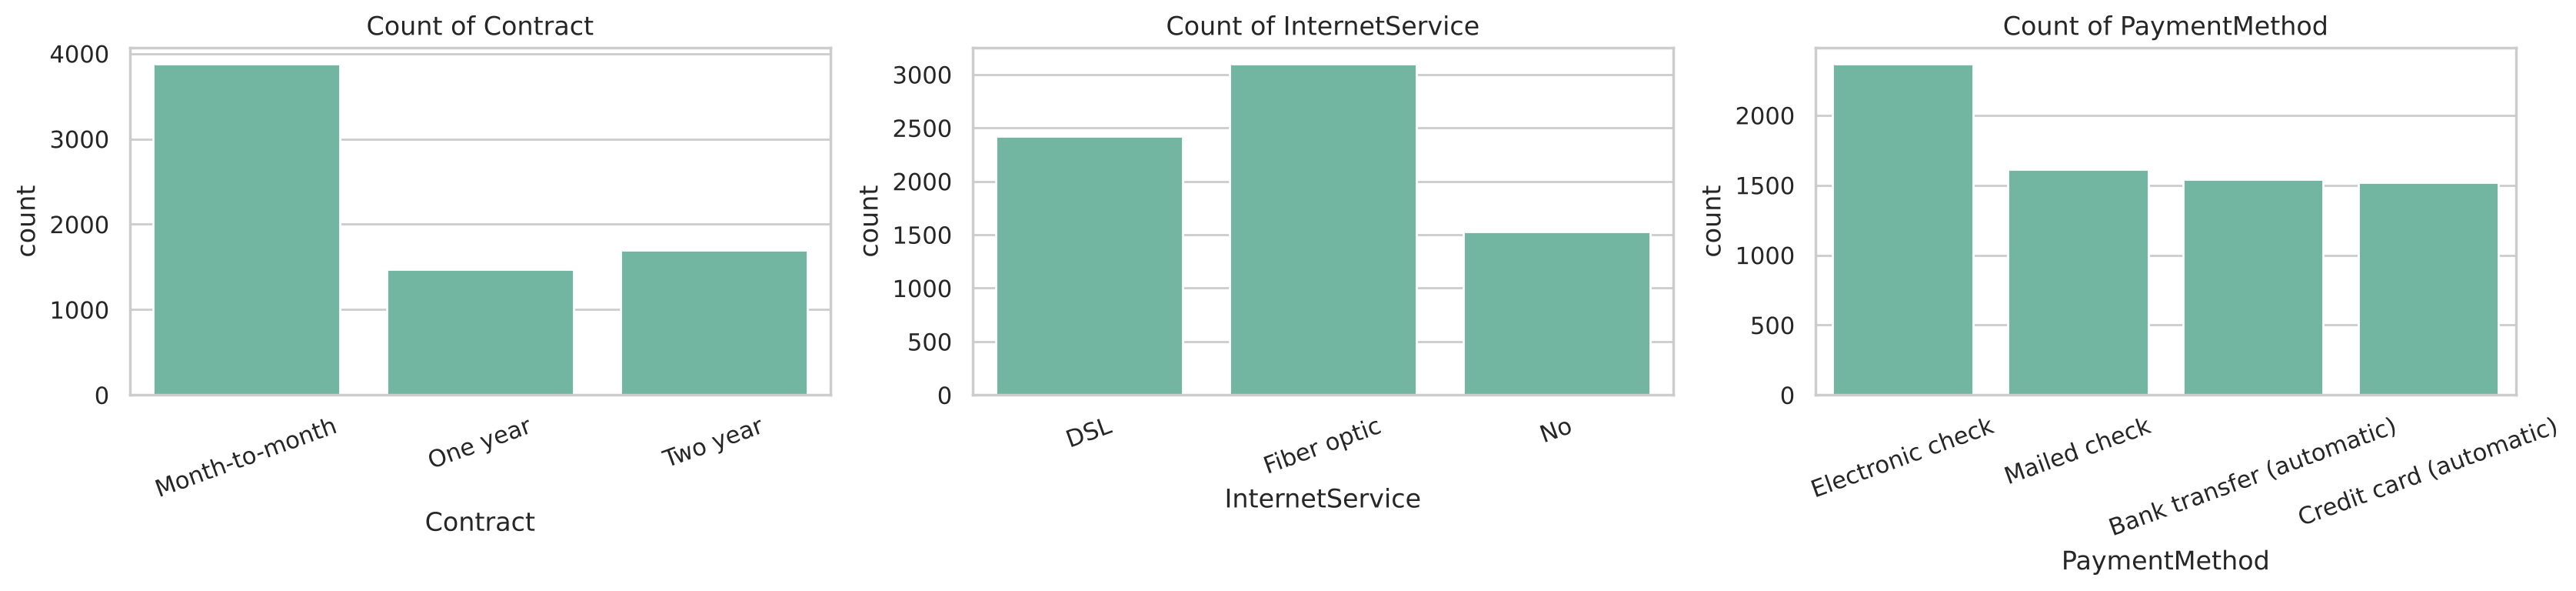

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=20)
savefig("03_categorical_countplots")

## 2.3 Bivariate Analysis

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn_bin, dtype: float64


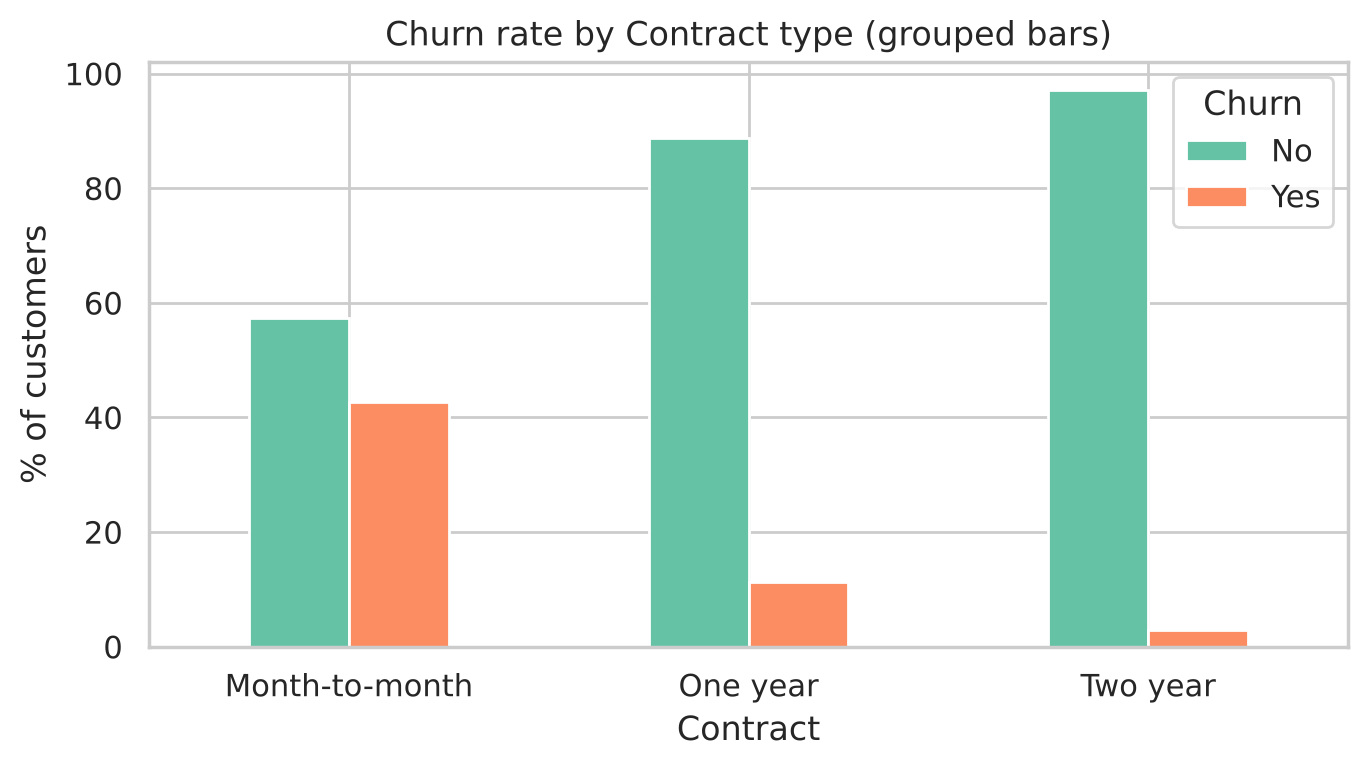

In [10]:
eda = df.copy()
eda["Churn_bin"] = eda["Churn"].map({"Yes": 1, "No": 0})

# Churn rate by contract
contract_rate = eda.groupby("Contract")["Churn_bin"].mean().mul(100).round(2)
print(contract_rate)

fig, ax = plt.subplots(figsize=(7, 4))
ct = pd.crosstab(eda["Contract"], eda["Churn"], normalize="index").mul(100)
ct.plot(kind="bar", ax=ax, rot=0)
ax.set_ylabel("% of customers"); ax.set_title("Churn rate by Contract type (grouped bars)")
savefig("04_churn_by_contract")

**Month-to-month** customers churn the most (**42.7%**) vs 11.3% on one-year and only 2.8% on two-year contracts.

tenure_bucket
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn_bin, dtype: float64


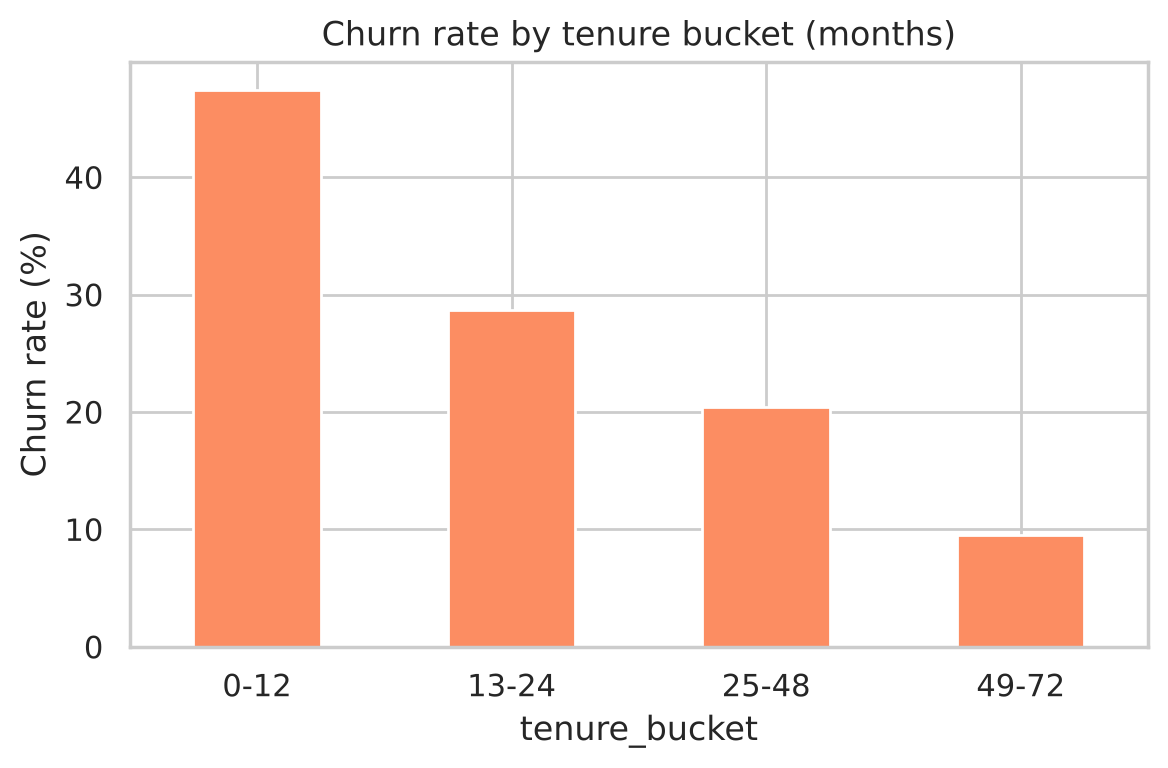

In [11]:
eda["tenure_bucket"] = pd.cut(eda["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
tb = eda.groupby("tenure_bucket")["Churn_bin"].mean().mul(100).round(2)
print(tb)
fig, ax = plt.subplots(figsize=(6, 4))
tb.plot(kind="bar", ax=ax, rot=0, color=sns.color_palette("Set2")[1])
ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate by tenure bucket (months)")
savefig("05_churn_by_tenure_bucket")

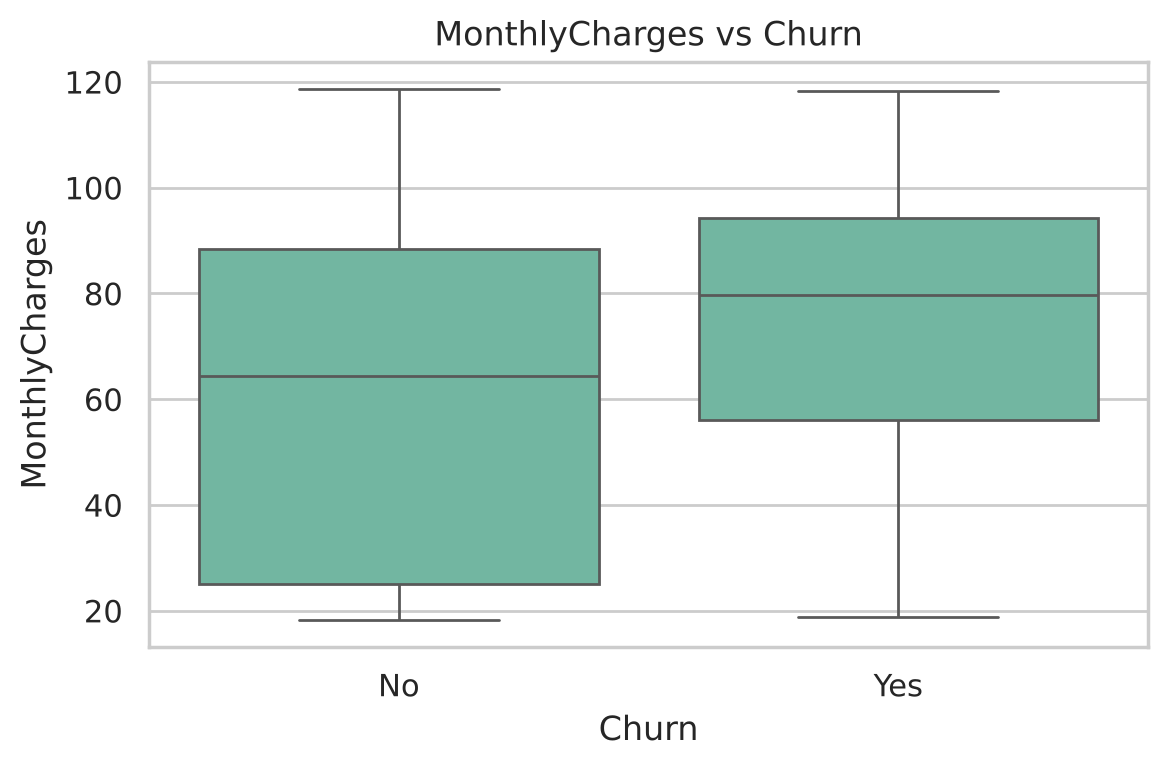

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("MonthlyCharges vs Churn")
savefig("06_boxplot_monthlycharges")
print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

**Yes** — churners pay more per month: mean ₹/$74.44 (median 79.65) vs 61.27 (median 64.43) for retained customers.

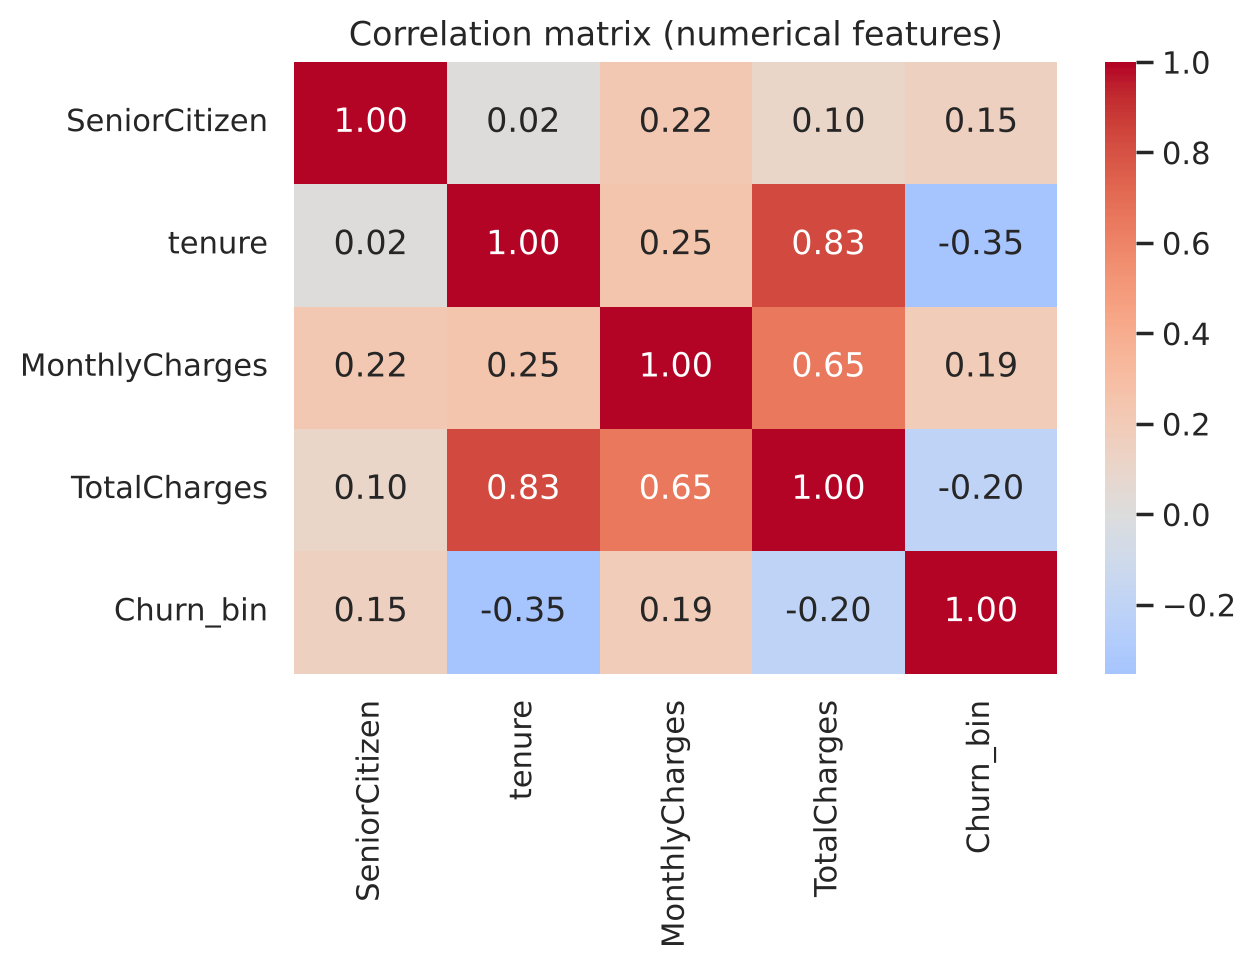

In [13]:
num_cols_eda = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_bin"]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(eda[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
savefig("07_correlation_heatmap")

`tenure` and `TotalCharges` are strongly correlated (**0.83**) — TotalCharges is roughly tenure × MonthlyCharges; `MonthlyCharges`–`TotalCharges` is 0.65. Churn is negatively correlated with `tenure` (−0.35) and `TotalCharges` (−0.20), and mildly positively with `MonthlyCharges` (+0.19). This multicollinearity matters for Naive Bayes.

In [14]:
# Key insight check: high-risk segment
seg = eda[(eda["Contract"] == "Month-to-month") & (eda["MonthlyCharges"] > eda["MonthlyCharges"].median()) & (eda["tenure"] <= 12)]
print(f"Segment (month-to-month, MonthlyCharges > median, tenure <= 12): n={len(seg)}, churn rate = {seg['Churn_bin'].mean()*100:.1f}%  vs overall {eda['Churn_bin'].mean()*100:.1f}%")

Segment (month-to-month, MonthlyCharges > median, tenure <= 12): n=812, churn rate = 70.0%  vs overall 26.5%


**Confirmed.** Customers on a month-to-month contract with above-median MonthlyCharges and tenure ≤ 12 months (812 customers) churn at **70.0%**, against 26.5% for the whole base — the highest-risk segment.

# 🔧 Step 3: Data Preprocessing & Feature Engineering

> **Order note (to avoid data leakage):** all *row-wise* transformations (cleaning, feature engineering, encoding) are done first on the whole frame — they don't learn anything from the data. Then we **split**, fit the `StandardScaler` on **train only**, and apply **SMOTE on train only**.

## 3.1 Drop & Clean

In [15]:
data = df.drop(columns=["customerID"]).copy()
median_tc = data["TotalCharges"].median()
data["TotalCharges"] = data["TotalCharges"].fillna(median_tc)
print("Median TotalCharges used:", median_tc, "| nulls left:", data.isna().sum().sum())

Median TotalCharges used: 1397.475 | nulls left: 0


## 3.2 Feature Engineering

In [16]:
data["tenure_group"] = pd.cut(data["tenure"], bins=[-1, 12, 36, 60, np.inf], labels=["New", "Mid", "Senior", "Loyal"])
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
data["num_services"] = (data[addons] == "Yes").sum(axis=1)
data["AutoPay"] = data["PaymentMethod"].str.contains("automatic", case=False).astype(int)
data[["tenure", "tenure_group", "num_services", "PaymentMethod", "AutoPay"]].head()

,tenure,tenure_group,num_services,PaymentMethod,AutoPay
0,1,New,1,Electronic check,0
1,34,Mid,2,Mailed check,0
2,2,New,2,Mailed check,0
3,45,Senior,3,Bank transfer (automatic),1
4,2,New,0,Electronic check,0


## 3.3 Encoding

In [17]:
# Binary columns: Yes -> 1, everything else ('No', 'No phone service', 'No internet service') -> 0
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "MultipleLines"] + addons
for c in binary_cols:
    data[c] = (data[c] == "Yes").astype(int)
data["gender"] = data["gender"].map({"Female": 0, "Male": 1})
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

# Label (ordinal) encoding of tenure_group, order preserved: New < Mid < Senior < Loyal
data["tenure_group"] = data["tenure_group"].map({"New": 0, "Mid": 1, "Senior": 2, "Loyal": 3}).astype(int)

# One-hot: InternetService, Contract, PaymentMethod (original columns are dropped by get_dummies)
data = pd.get_dummies(data, columns=["InternetService", "Contract", "PaymentMethod"], dtype=int)
print("Shape after encoding:", data.shape)
print("All numeric?", all(pd.api.types.is_numeric_dtype(t) for t in data.dtypes))
data.head()

Shape after encoding: (7043, 30)
All numeric? True


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


## 3.6 Train-Test Split (80/20, stratified)

In [18]:
X = data.drop(columns="Churn")
y = data["Churn"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("X_train:", X_train_raw.shape, "| X_test:", X_test_raw.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (5634, 29) | X_test: (1409, 29)
y_train: (5634,) | y_test: (1409,)


## 3.4 Scaling (StandardScaler — fit on train only)

In [19]:
scale_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
scaler = StandardScaler().fit(X_train_raw[scale_cols])

X_train, X_test = X_train_raw.copy(), X_test_raw.copy()
X_train[scale_cols] = scaler.transform(X_train_raw[scale_cols])
X_test[scale_cols] = scaler.transform(X_test_raw[scale_cols])
X_train[scale_cols].describe().loc[["mean", "std"]].round(3)

,tenure,MonthlyCharges,TotalCharges,num_services
mean,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


## 3.5 Handle Class Imbalance (SMOTE on training set only)

In [20]:
print("Training-set class counts BEFORE SMOTE:\n", y_train.value_counts().to_string())
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("\nTraining-set class counts AFTER SMOTE:\n", y_train_sm.value_counts().to_string())
print("\nTest set (untouched):\n", y_test.value_counts().to_string())

Training-set class counts BEFORE SMOTE:
 Churn
0    4139
1    1495

Training-set class counts AFTER SMOTE:
 Churn
0    4139
1    4139

Test set (untouched):
 Churn
0    1035
1     374


In [21]:
# Sanity check: our step-by-step preprocessing == the reusable module used by the final pipeline
chk = cf.engineer(df, totalcharges_median=median_tc)
pd.testing.assert_frame_equal(chk[X.columns], X, check_dtype=False)
print("churn_features.engineer() reproduces the notebook feature matrix exactly ✅")

churn_features.engineer() reproduces the notebook feature matrix exactly ✅


# 🛠️ Evaluation helpers

In [22]:
store = {}   # name -> dict(model, metrics, proba, pred, train_time)

def fit_timed(model, X, y):
    t0 = time.perf_counter(); model.fit(X, y)
    return model, time.perf_counter() - t0

def evaluate(model, X, y_true):
    pred = model.predict(X); proba = model.predict_proba(X)[:, 1]
    m = dict(Accuracy=accuracy_score(y_true, pred), Precision=precision_score(y_true, pred),
             Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred), AUC=roc_auc_score(y_true, proba))
    return m, pred, proba

def show_metrics(title, m):
    print(f"{title:<34}" + " | ".join(f"{k}: {v:.4f}" for k, v in m.items()))

def plot_cm(y_true, pred, title, fname):
    fig, ax = plt.subplots(figsize=(4.6, 4))
    sns.heatmap(confusion_matrix(y_true, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    savefig(fname)

def plot_roc(y_true, proba, title, fname):
    fpr, tpr, _ = roc_curve(y_true, proba)
    fig, ax = plt.subplots(figsize=(5, 4.3))
    ax.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_true, proba):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.set_title(title); ax.legend(loc="lower right")
    savefig(fname)

def register(name, model, train_time):
    m, pred, proba = evaluate(model, X_test, y_test)
    store[name] = dict(model=model, metrics=m, pred=pred, proba=proba, train_time=train_time)
    return m

# 🤖 Step 4: Model Building — KNN & Naive Bayes

## 4.1 K-Nearest Neighbours

In [23]:
# Baseline k=5 (trained on SMOTE-balanced training data)
knn5, _ = fit_timed(KNeighborsClassifier(n_neighbors=5), X_train_sm, y_train_sm)
m5, _, _ = evaluate(knn5, X_test, y_test)
show_metrics("KNN baseline (k=5) — test", m5)

KNN baseline (k=5) — test         Accuracy: 0.7331 | Precision: 0.4982 | Recall: 0.7326 | F1: 0.5931 | AUC: 0.7931


**Tuning k** — we hold out a validation set (20% of the *training* data, SMOTE applied only to the remaining 80%) so the test set stays untouched.

{1: np.float64(0.5156), 3: np.float64(0.5583), 5: np.float64(0.5887), 7: np.float64(0.5937), 9: np.float64(0.5819), 11: np.float64(0.5935), 15: np.float64(0.6054)}
Best k = 15


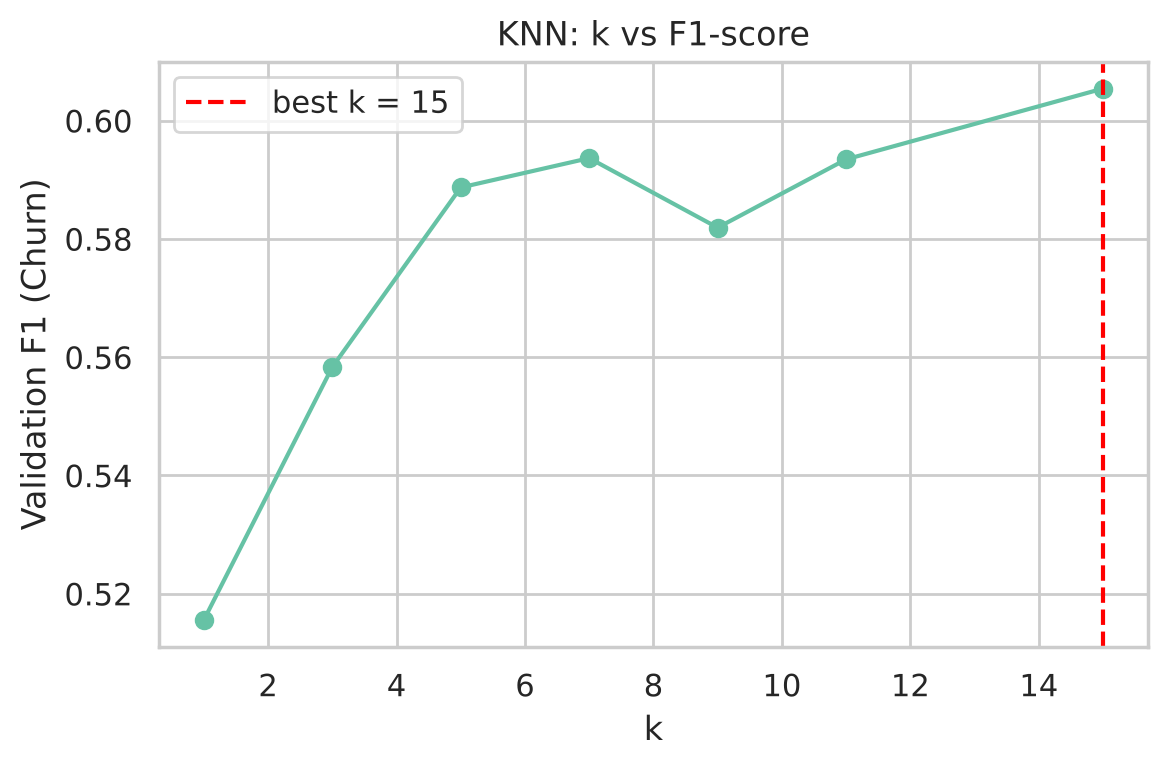

In [24]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
X_tr_sm, y_tr_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)

ks = [1, 3, 5, 7, 9, 11, 15]
knn_f1 = []
for k in ks:
    mdl = KNeighborsClassifier(n_neighbors=k).fit(X_tr_sm, y_tr_sm)
    knn_f1.append(f1_score(y_val, mdl.predict(X_val)))
best_k = ks[int(np.argmax(knn_f1))]
print(dict(zip(ks, np.round(knn_f1, 4))))
print("Best k =", best_k)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ks, knn_f1, marker="o"); ax.axvline(best_k, color="red", ls="--", label=f"best k = {best_k}")
ax.set_xlabel("k"); ax.set_ylabel("Validation F1 (Churn)"); ax.set_title("KNN: k vs F1-score"); ax.legend()
savefig("08_knn_k_vs_f1")

KNN tuned (k=15) — test           Accuracy: 0.7268 | Precision: 0.4909 | Recall: 0.7941 | F1: 0.6067 | AUC: 0.8152
              precision    recall  f1-score   support

    No Churn       0.90      0.70      0.79      1035
       Churn       0.49      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.73      0.74      1409



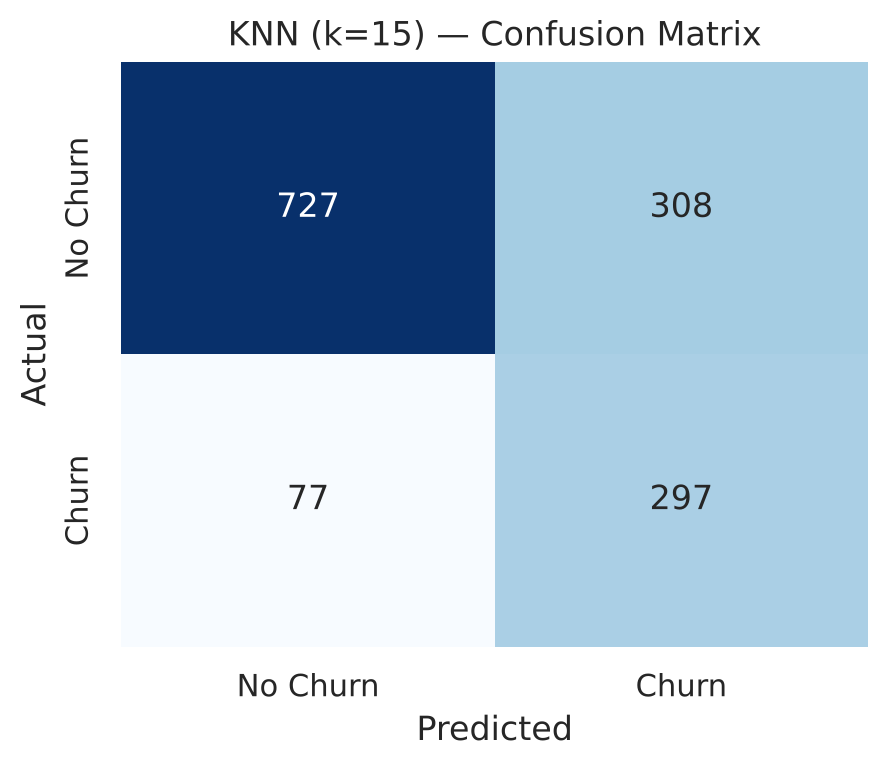

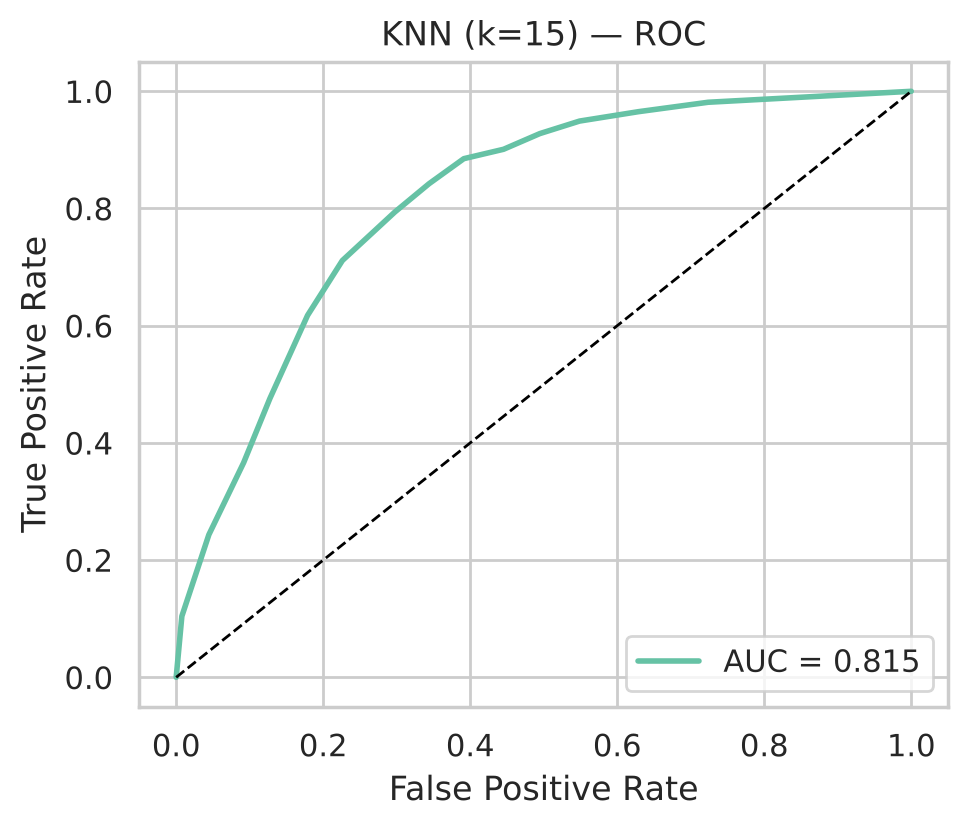

In [25]:
knn, t = fit_timed(KNeighborsClassifier(n_neighbors=best_k), X_train_sm, y_train_sm)
m = register("KNN", knn, t)
show_metrics(f"KNN tuned (k={best_k}) — test", m)
print(classification_report(y_test, store["KNN"]["pred"], target_names=["No Churn", "Churn"]))
plot_cm(y_test, store["KNN"]["pred"], f"KNN (k={best_k}) — Confusion Matrix", "09_knn_confusion_matrix")
plot_roc(y_test, store["KNN"]["proba"], f"KNN (k={best_k}) — ROC", "10_knn_roc")

**Best k = 15** on the validation set (F1 ≈ 0.605); k = 1 overfits badly (F1 ≈ 0.52) and F1 gradually improves with larger k as the vote becomes smoother. Tuned KNN has the **highest churn Recall (0.794)** but the lowest precision (0.49), and it must store and scan the whole training set at prediction time.

## 4.2 Gaussian Naive Bayes

GaussianNB — test                 Accuracy: 0.7360 | Precision: 0.5017 | Recall: 0.7861 | F1: 0.6125 | AUC: 0.8217
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

class_prior_ learned (trained on SMOTE data): [0.5 0.5]
Actual churn rate in original training set  : [0.7346 0.2654]


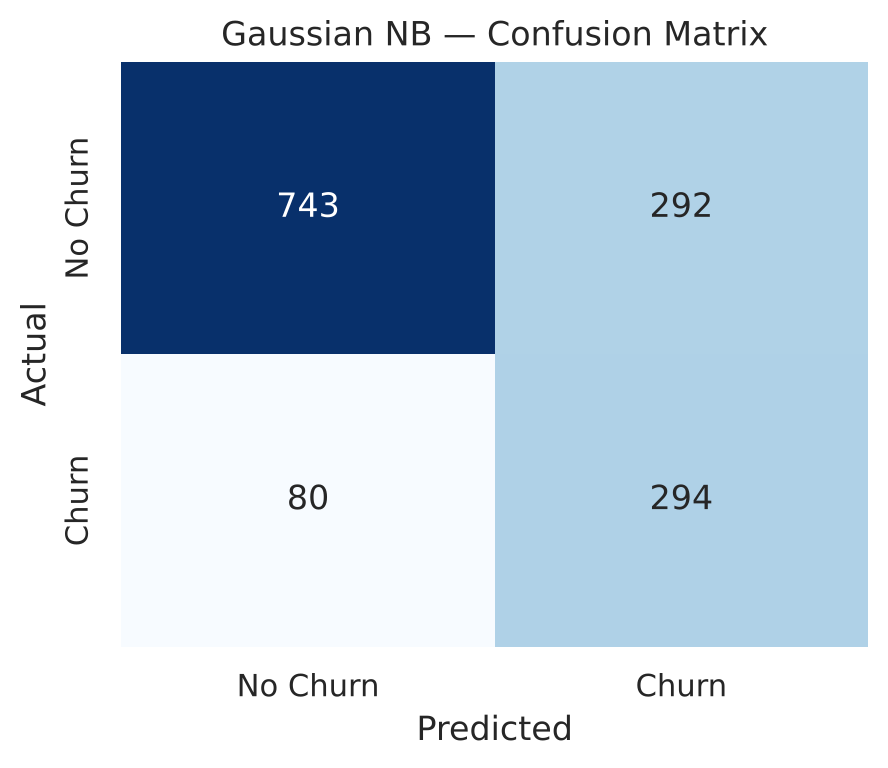

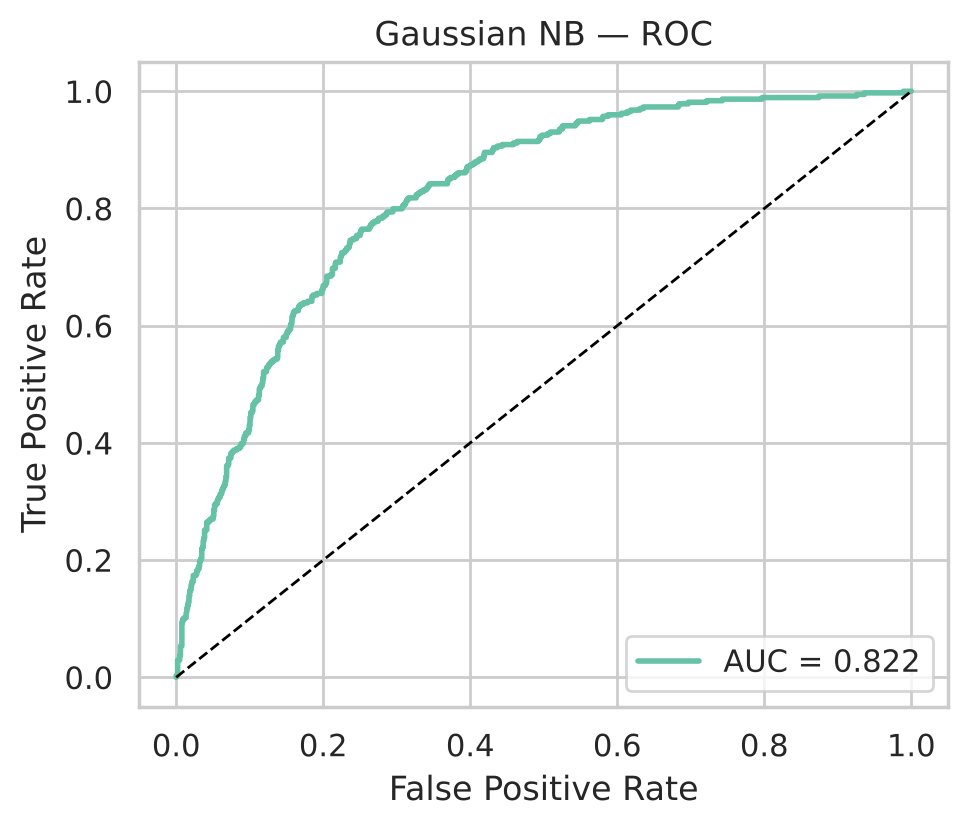

In [26]:
nb, t = fit_timed(GaussianNB(), X_train_sm, y_train_sm)
m = register("Naive Bayes", nb, t)
show_metrics("GaussianNB — test", m)
print(classification_report(y_test, store["Naive Bayes"]["pred"], target_names=["No Churn", "Churn"]))

print("class_prior_ learned (trained on SMOTE data):", nb.class_prior_.round(4))
print("Actual churn rate in original training set  :", y_train.value_counts(normalize=True).sort_index().round(4).values)
plot_cm(y_test, store["Naive Bayes"]["pred"], "Gaussian NB — Confusion Matrix", "11_nb_confusion_matrix")
plot_roc(y_test, store["Naive Bayes"]["proba"], "Gaussian NB — ROC", "12_nb_roc")

**class_prior_ = [0.5, 0.5]** — it does **not** match the real churn rate (26.5%) because the model was trained on SMOTE-balanced data where both classes are equal. This pushes the model to predict churn more readily → high recall, lower precision. (On the original data the prior would be ≈ [0.73, 0.27].)

**Independence assumption:** it does **not** hold well here — `tenure`, `TotalCharges` and `MonthlyCharges` are strongly correlated (r = 0.83 / 0.65), and add-on services and InternetService categories move together. NB still ranks customers reasonably (AUC ≈ 0.82), but its probabilities are over-confident and poorly calibrated.

# 🧮 Step 5: Model Building — SVM & Decision Tree

## 5.1 Support Vector Machine

SVM baseline (C=1) — test         Accuracy: 0.7715 | Precision: 0.5565 | Recall: 0.6845 | F1: 0.6139 | AUC: 0.8205


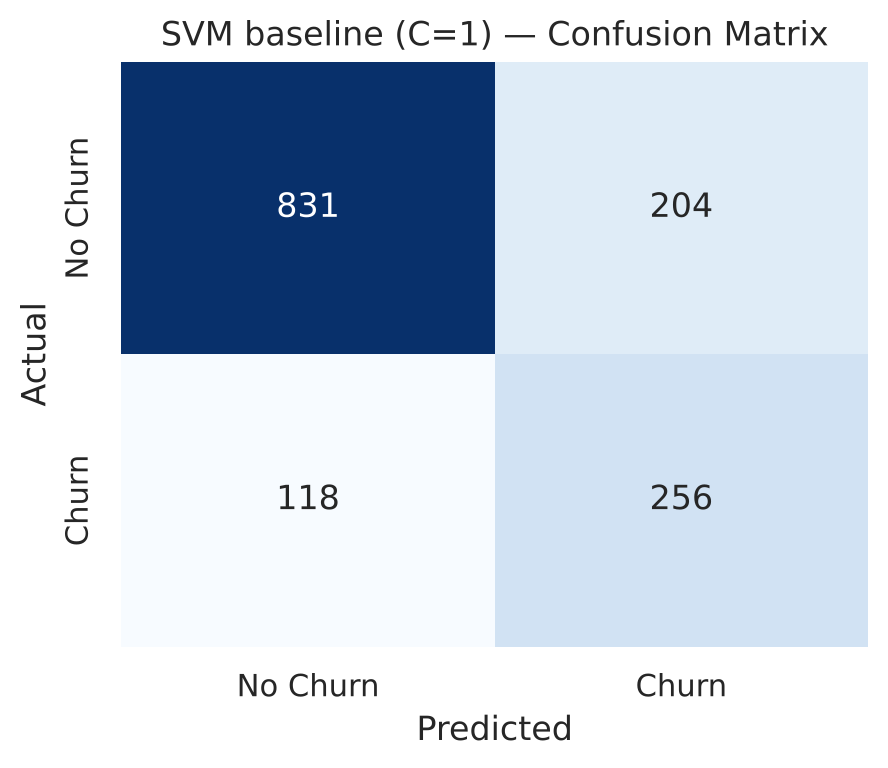

In [27]:
svm0, t0 = fit_timed(SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=RANDOM_STATE), X_train_sm, y_train_sm)
m0, p0, _ = evaluate(svm0, X_test, y_test)
show_metrics("SVM baseline (C=1) — test", m0)
plot_cm(y_test, p0, "SVM baseline (C=1) — Confusion Matrix", "13_svm_baseline_confusion_matrix")

**Tuning C** with 3-fold CV (`scoring='f1'`). SMOTE is placed *inside* an `imblearn` pipeline so it is applied only on each fold's training part (no synthetic-sample leakage into validation folds).

{0.1: np.float64(0.6303), 1: np.float64(0.6237), 10: np.float64(0.588), 100: np.float64(0.5437)}
Best C = 0.1


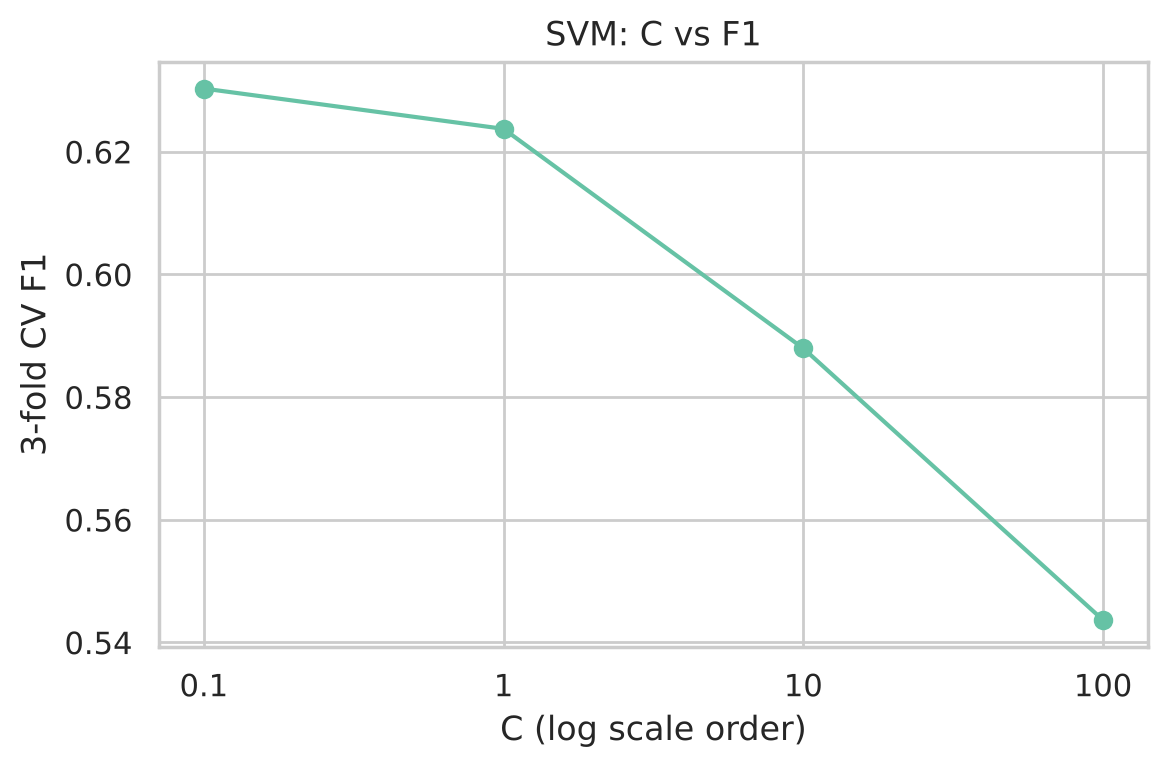

In [28]:
Cs = [0.1, 1, 10, 100]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
svm_f1 = []
for Cval in Cs:
    pipe = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("svc", SVC(kernel="rbf", C=Cval, gamma="scale", random_state=RANDOM_STATE))])
    svm_f1.append(cross_val_score(pipe, X_train, y_train, cv=cv3, scoring="f1", n_jobs=-1).mean())
best_C = Cs[int(np.argmax(svm_f1))]
print(dict(zip(Cs, np.round(svm_f1, 4)))); print("Best C =", best_C)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(len(Cs)), svm_f1, marker="o"); ax.set_xticks(range(len(Cs))); ax.set_xticklabels(Cs)
ax.set_xlabel("C (log scale order)"); ax.set_ylabel("3-fold CV F1"); ax.set_title("SVM: C vs F1")
savefig("14_svm_C_vs_f1")

SVM tuned (C=0.1) — test          Accuracy: 0.7495 | Precision: 0.5194 | Recall: 0.7513 | F1: 0.6142 | AUC: 0.8286
              precision    recall  f1-score   support

    No Churn       0.89      0.75      0.81      1035
       Churn       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



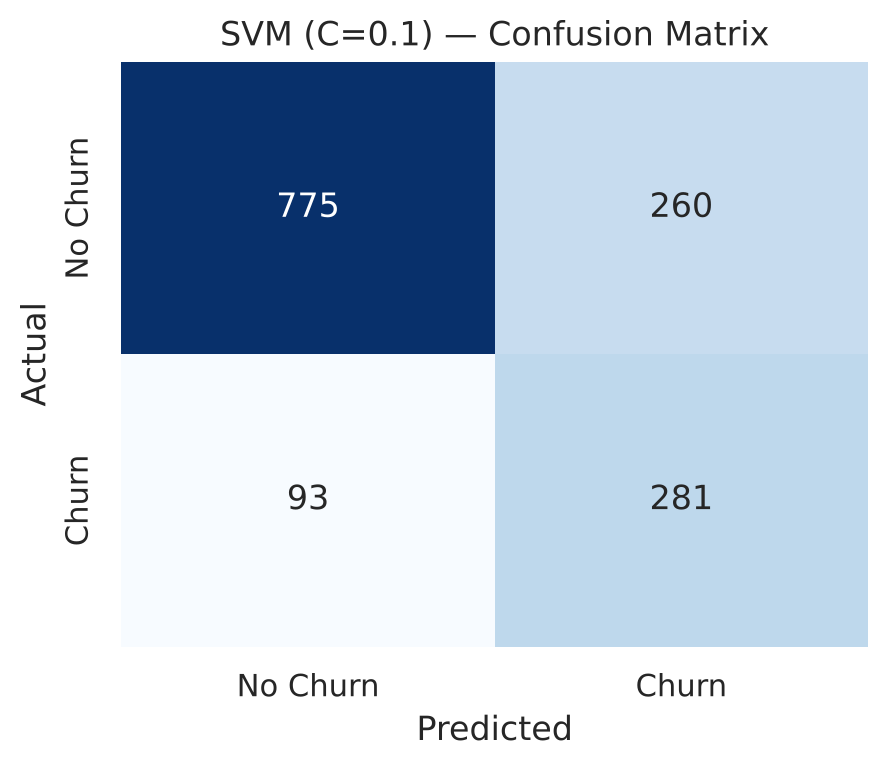

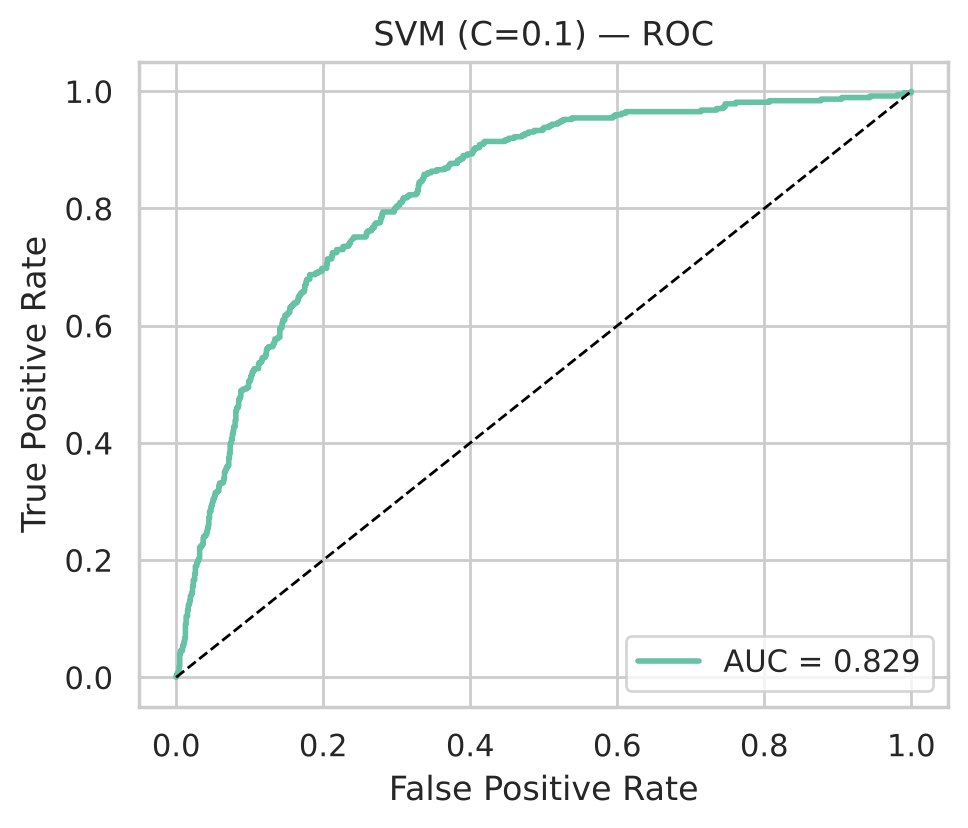

In [29]:
svm, t = fit_timed(SVC(kernel="rbf", C=best_C, gamma="scale", probability=True, random_state=RANDOM_STATE), X_train_sm, y_train_sm)
m = register("SVM", svm, t)
show_metrics(f"SVM tuned (C={best_C}) — test", m)
print(classification_report(y_test, store["SVM"]["pred"], target_names=["No Churn", "Churn"]))
plot_cm(y_test, store["SVM"]["pred"], f"SVM (C={best_C}) — Confusion Matrix", "15_svm_confusion_matrix")
plot_roc(y_test, store["SVM"]["proba"], f"SVM (C={best_C}) — ROC", "16_svm_roc")

**Best C = 0.1** (CV F1 ≈ 0.63) — a *smoother* boundary generalises better; large C (100) overfits (F1 ≈ 0.54).

**Interpretability vs performance:** the RBF-SVM gives the best AUC (0.829) but is a black box — we cannot easily tell a manager *why* a customer was flagged, which makes it hard to design a targeted offer or defend the decision. Its gain over a transparent Decision Tree is small here, so a business that needs explainable, actionable rules may happily trade a little performance for interpretability.

## 5.2 Decision Tree

Decision Tree baseline (depth=5)  Accuracy: 0.7559 | Precision: 0.5267 | Recall: 0.7914 | F1: 0.6325 | AUC: 0.8353


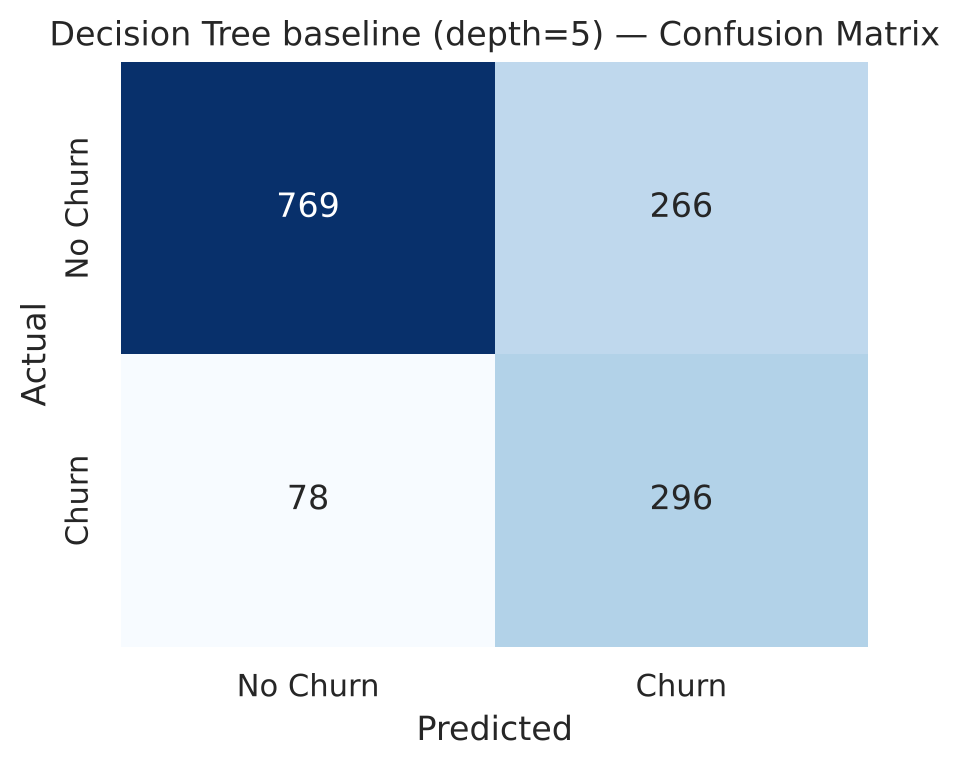

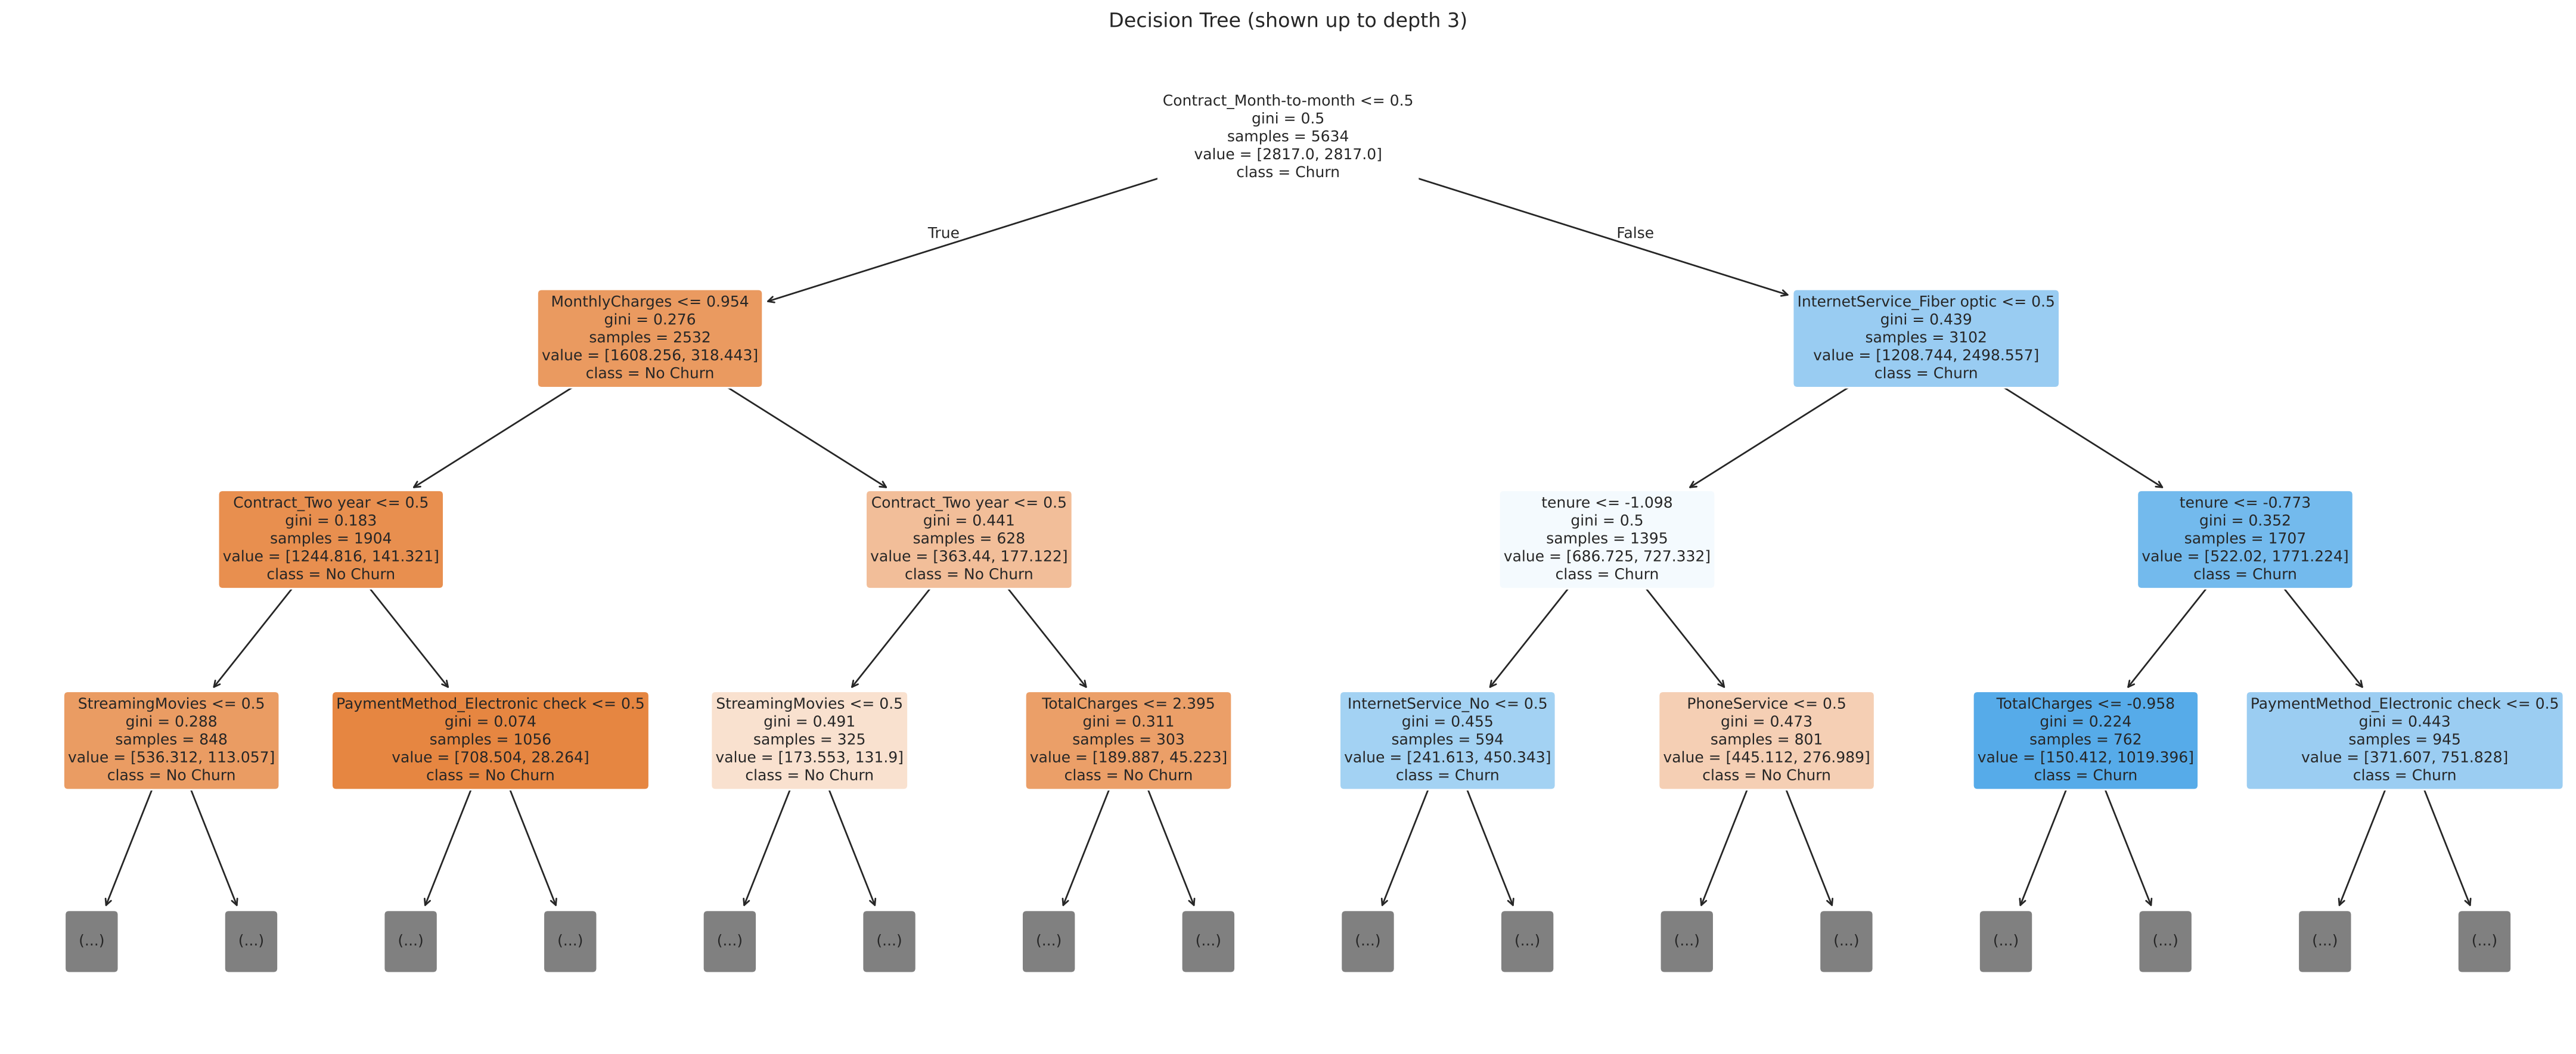

ROOT SPLIT FEATURE: Contract_Month-to-month <= 0.5 (scaled / 0-1 units)


In [30]:
dt0, t0 = fit_timed(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE), X_train, y_train)
m0, p0, _ = evaluate(dt0, X_test, y_test)
show_metrics("Decision Tree baseline (depth=5)", m0)
plot_cm(y_test, p0, "Decision Tree baseline (depth=5) — Confusion Matrix", "17_dt_baseline_confusion_matrix")

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt0, max_depth=3, feature_names=X.columns, class_names=["No Churn", "Churn"], filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree (shown up to depth 3)")
savefig("18_decision_tree_plot")
print("ROOT SPLIT FEATURE:", X.columns[dt0.tree_.feature[0]], "<=", round(dt0.tree_.threshold[0], 3), "(scaled / 0-1 units)")

{'3': np.float64(0.6204), '4': np.float64(0.6084), '5': np.float64(0.6137), '6': np.float64(0.6151), '7': np.float64(0.6118), '8': np.float64(0.5983), 'None': np.float64(0.4999)}
Best depth = 3


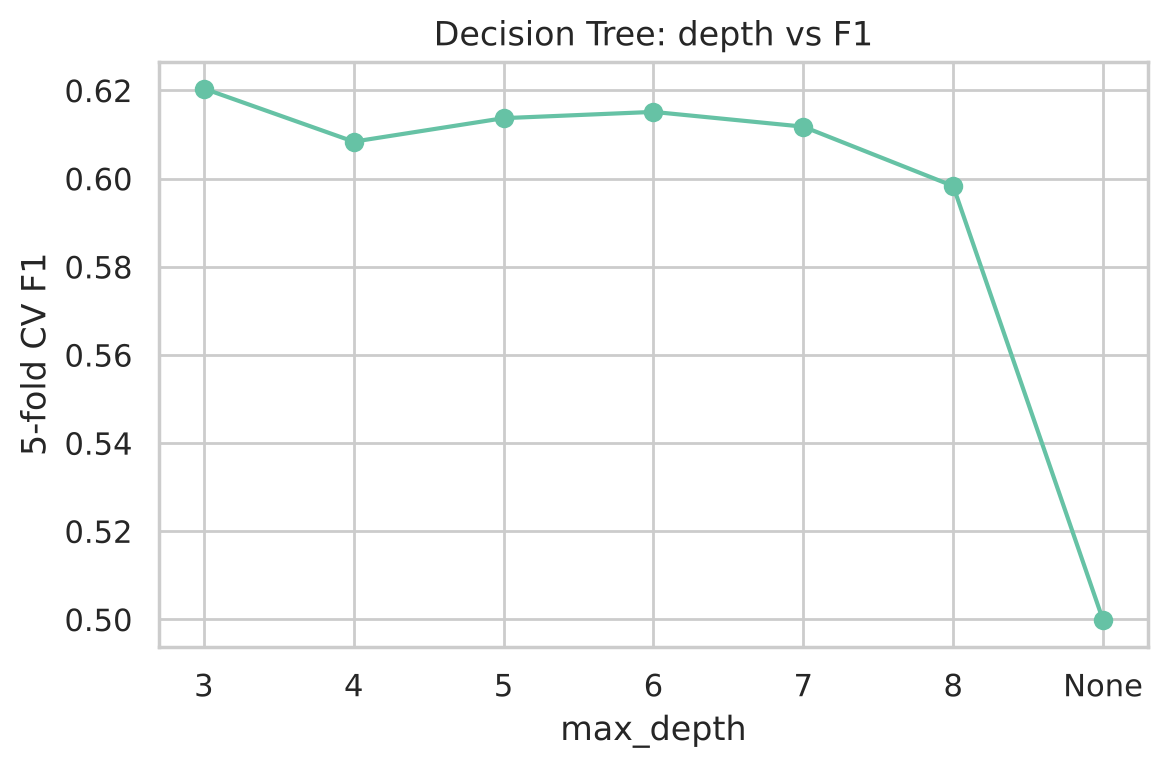

In [31]:
depths = [3, 4, 5, 6, 7, 8, None]
dt_f1 = [cross_val_score(DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE),
                         X_train, y_train, cv=5, scoring="f1").mean() for d in depths]
best_depth = depths[int(np.argmax(dt_f1))]
print(dict(zip(map(str, depths), np.round(dt_f1, 4)))); print("Best depth =", best_depth)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([str(d) for d in depths], dt_f1, marker="o"); ax.set_xlabel("max_depth"); ax.set_ylabel("5-fold CV F1")
ax.set_title("Decision Tree: depth vs F1")
savefig("19_dt_depth_vs_f1")

Decision Tree (depth=3) — test    Accuracy: 0.7459 | Precision: 0.5140 | Recall: 0.7834 | F1: 0.6208 | AUC: 0.8162
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



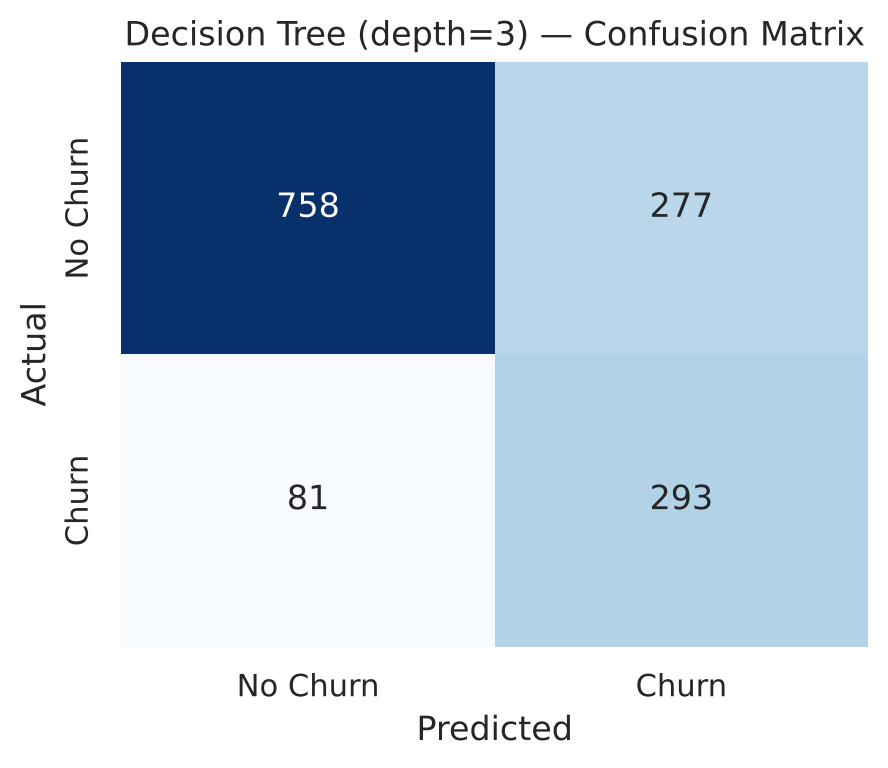

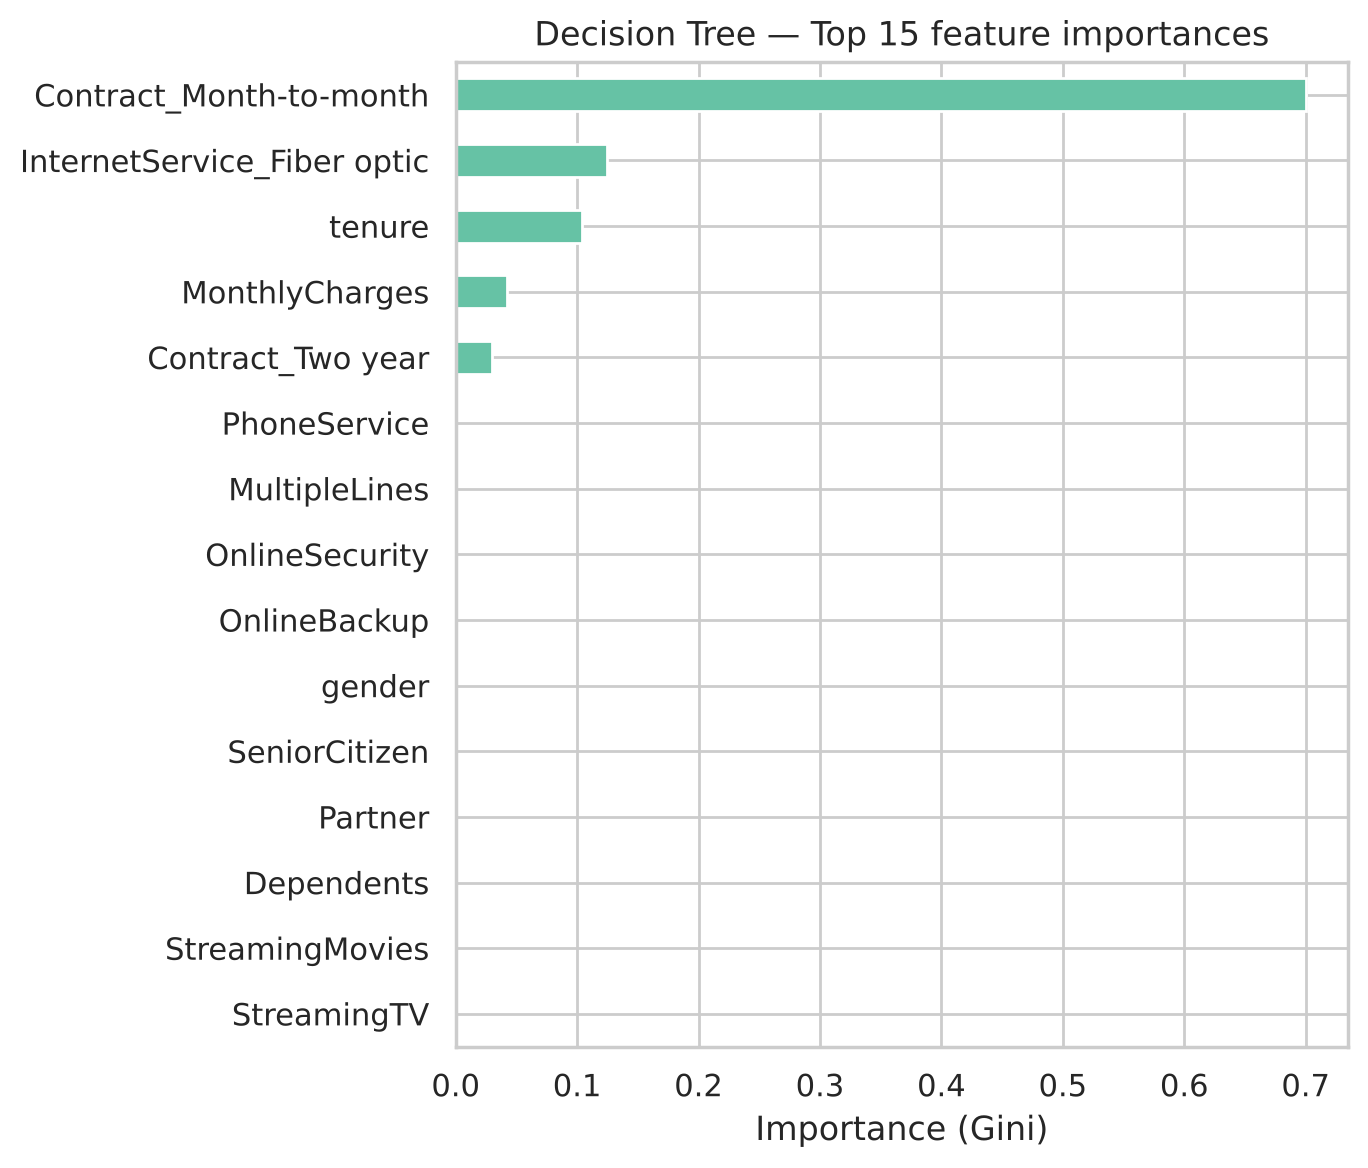

In [32]:
dt, t = fit_timed(DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE), X_train, y_train)
m = register("Decision Tree", dt, t)
show_metrics(f"Decision Tree (depth={best_depth}) — test", m)
print(classification_report(y_test, store["Decision Tree"]["pred"], target_names=["No Churn", "Churn"]))
plot_cm(y_test, store["Decision Tree"]["pred"], f"Decision Tree (depth={best_depth}) — Confusion Matrix", "20_dt_confusion_matrix")

imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 6)); top15.plot(kind="barh", ax=ax, color=sns.color_palette("Set2")[0])
ax.set_title("Decision Tree — Top 15 feature importances"); ax.set_xlabel("Importance (Gini)")
savefig("21_dt_feature_importance")

## 5.3 `class_weight='balanced'` vs SMOTE (best model so far)

In [33]:
best_so_far = max(store, key=lambda n: store[n]["metrics"]["F1"])
print("Best model so far (by Churn F1):", best_so_far)

final_params = {"KNN": dict(n_neighbors=best_k), "Naive Bayes": {}, "SVM": dict(C=best_C), "Decision Tree": dict(max_depth=best_depth)}

def build(name, balanced=False, proba=True):
    p = final_params[name]
    if name == "SVM":
        return SVC(kernel="rbf", gamma="scale", probability=proba, random_state=RANDOM_STATE,
                   class_weight="balanced" if balanced else None, **p)
    if name == "Decision Tree":
        return DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced" if balanced else None, **p)
    if name == "Naive Bayes":                       # no class_weight in GaussianNB -> equal priors is the equivalent
        return GaussianNB(priors=[0.5, 0.5] if balanced else None)
    return KNeighborsClassifier(weights="distance" if balanced else "uniform", **p)   # KNN: closest equivalent

a, _ = fit_timed(build(best_so_far, balanced=False), X_train_sm, y_train_sm)          # SMOTE data
b, _ = fit_timed(build(best_so_far, balanced=True),  X_train, y_train)                # original + class_weight
ma, _, _ = evaluate(a, X_test, y_test); mb, _, _ = evaluate(b, X_test, y_test)

cmp53 = pd.DataFrame({"SMOTE (augmented train)": ma, "class_weight='balanced' (original train)": mb}).T.round(4)
cmp53

Best model so far (by Churn F1): Decision Tree


,Accuracy,Precision,Recall,F1,AUC
SMOTE (augmented train),0.7488,0.5184,0.7540,0.6144,0.8096
class_weight='balanced' (original train),0.7459,0.5140,0.7834,0.6208,0.8162


**Decision Tree was the best model so far (highest F1).** `class_weight='balanced'` on the original data gives **Recall 0.783** vs **0.754** with SMOTE (and slightly higher F1 and AUC too). So for this model **class_weight='balanced' is better for Churn recall** — and it is also simpler and cheaper: no synthetic rows, no extra step. SMOTE's synthetic points help distance-based models (KNN/SVM) more than a tree, which only needs the loss re-weighted.

# 📈 Step 6: Model Evaluation & Comparison

In [34]:
comparison = pd.DataFrame({
    n: {"Accuracy": s["metrics"]["Accuracy"], "Precision (Churn)": s["metrics"]["Precision"],
        "Recall (Churn)": s["metrics"]["Recall"], "F1 (Churn)": s["metrics"]["F1"],
        "AUC-ROC": s["metrics"]["AUC"], "Training Time (s)": s["train_time"]}
    for n, s in store.items()}).T.sort_values("Recall (Churn)", ascending=False)
comparison.style.format("{:.4f}").background_gradient(cmap="Greens", subset=comparison.columns[:-1]).background_gradient(cmap="Reds", subset=["Training Time (s)"])

,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Training Time (s)
KNN,0.7268,0.4909,0.7941,0.6067,0.8152,0.0037
Naive Bayes,0.7360,0.5017,0.7861,0.6125,0.8217,0.0073
Decision Tree,0.7459,0.5140,0.7834,0.6208,0.8162,0.0093
SVM,0.7495,0.5194,0.7513,0.6142,0.8286,10.6532


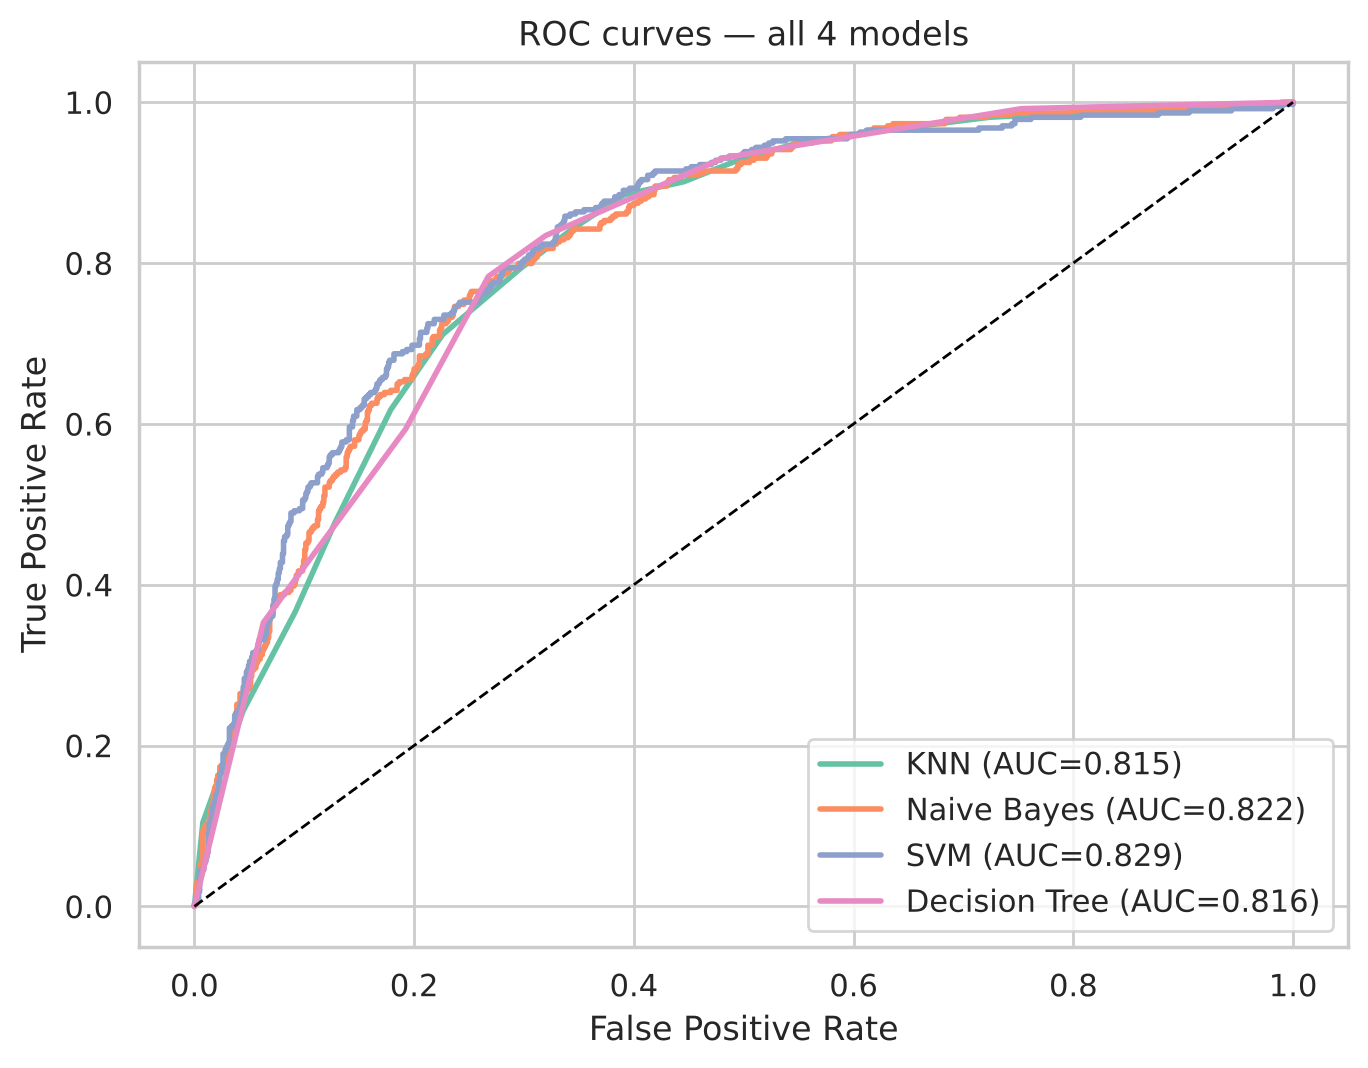

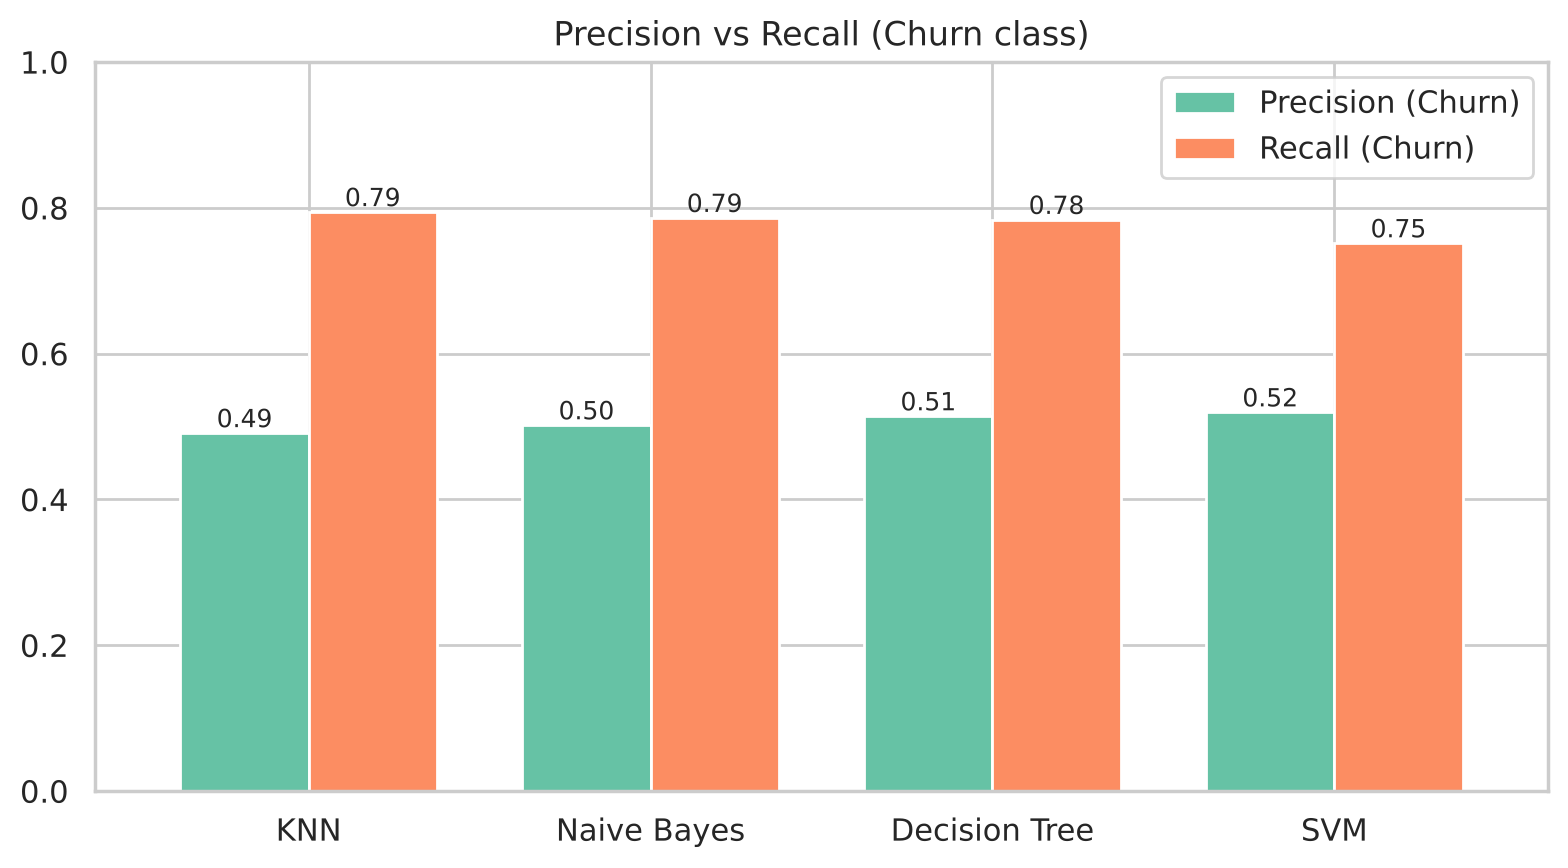

In [35]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for n, s in store.items():
    fpr, tpr, _ = roc_curve(y_test, s["proba"]); ax.plot(fpr, tpr, lw=2, label=f"{n} (AUC={s['metrics']['AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — all 4 models"); ax.legend(loc="lower right")
savefig("22_all_roc_curves")

pr = comparison[["Precision (Churn)", "Recall (Churn)"]]
ax = pr.plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75)
ax.set_title("Precision vs Recall (Churn class)"); ax.set_ylim(0, 1)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
savefig("23_precision_vs_recall")

### Recommendation
**Deploy the Decision Tree (depth 3, `class_weight='balanced'`).** Its churn Recall (0.78) is within ~1 point of the best (KNN 0.79, NB 0.79) while it has the **best F1 (0.62)** and a better precision than KNN/NB, so the retention team wastes fewer calls on loyal customers. SVM has the best AUC (0.829) but the lowest Recall (0.75) and is hundreds of times slower to train and a black box. KNN's marginal recall edge comes with the lowest precision and slow prediction (it scans all training rows per customer). The tree predicts in well under a millisecond, and its rules (month-to-month contract → fibre → short tenure) can be explained directly to marketing, who can design offers per segment. Since the team can call only ~500 customers/day, we can also rank customers by predicted probability and call the top 500 instead of using the 0.5 threshold.

# 🔍 Step 7: Error Analysis & Interpretation

## 7.1 Error analysis on the best (deployment) model

In [36]:
deploy_name = best_so_far
print("Deployment model:", deploy_name)
pred = store[deploy_name]["pred"]

test_df = X_test_raw.copy()                                 # un-scaled values, readable units
test_df["actual"] = y_test.values; test_df["pred"] = pred
test_df["Contract"] = test_df[[c for c in X.columns if c.startswith("Contract_")]].idxmax(axis=1).str.replace("Contract_", "")

fn = test_df[(test_df.actual == 1) & (test_df.pred == 0)]
churners = test_df[test_df.actual == 1]
caught = test_df[(test_df.actual == 1) & (test_df.pred == 1)]
print(f"False negatives: {len(fn)} of {len(churners)} real churners in the test set\n")

profile = pd.DataFrame({"Missed churners (FN)": [fn.tenure.mean(), fn.MonthlyCharges.mean(), fn.num_services.mean()],
                        "Caught churners (TP)": [caught.tenure.mean(), caught.MonthlyCharges.mean(), caught.num_services.mean()],
                        "All churners":         [churners.tenure.mean(), churners.MonthlyCharges.mean(), churners.num_services.mean()]},
                       index=["avg tenure (months)", "avg MonthlyCharges", "avg num_services"]).round(2)
display(profile)
display(pd.DataFrame({"FN": fn.Contract.value_counts(normalize=True).mul(100).round(1),
                      "All churners": churners.Contract.value_counts(normalize=True).mul(100).round(1)}).fillna(0).rename_axis("Contract (%)"))

Deployment model: Decision Tree
False negatives: 81 of 374 real churners in the test set



,Missed churners (FN),Caught churners (TP),All churners
avg tenure (months),33.83,11.66,16.46
avg MonthlyCharges,67.80,74.14,72.77
avg num_services,2.59,1.39,1.65


,FN,All churners
Contract (%),,
Month-to-month,44.4,88.0
One year,44.4,9.6
Two year,11.1,2.4


**Pattern:** the model misses **'unexpected' churners**. Missed churners have an average tenure of **33.8 months** (caught churners: 11.7; all churners: 16.5), use more add-on services (2.6 vs 1.4), pay less per month (67.8 vs 74.1), and 56% of them are on one-/two-year contracts (all churners: only 12%). They look like safe, committed customers — they don't match the 'new, month-to-month, high-bill' stereotype the tree relies on. To catch them we would need extra signals (support tickets, usage drop, contract-expiry date, competitor offers), because the current features simply don't describe why they leave.

## 7.2 Feature importance / decision insight

In [37]:
print("Top-5 Decision Tree split features (by importance):")
top5 = imp.head(5).round(4); display(top5.to_frame("importance"))
print("Root split:", X.columns[dt.tree_.feature[0]])

Top-5 Decision Tree split features (by importance):


,importance
Contract_Month-to-month,0.6999
InternetService_Fiber optic,0.1242
tenure,0.1038
MonthlyCharges,0.0423
Contract_Two year,0.0298


Root split: Contract_Month-to-month


- **Contract_Month-to-month (importance ≈ 0.70, root split):** the single most informative signal — customers without a lock-in can leave any time.
- **InternetService_Fiber optic (≈ 0.12):** fibre customers churn at 41.9% (DSL 19.0%) — higher price and/or service-quality / competition issues.
- **tenure (≈ 0.10):** the newer the customer, the higher the risk; early months are the danger zone.
- **MonthlyCharges (≈ 0.04):** high bills push churn up, especially inside the short-tenure branch.
- **Contract_Two year (≈ 0.03):** two-year customers are almost never lost (2.8% churn) — it refines the contract split.

### Business-friendly insights
- Customers on **month-to-month contracts churn at 42.7%** vs 2.8% on two-year (≈ 15× higher) — the tree's very first split. Push upgrades to 1/2-year plans with a discount or free add-on.
- **First-year customers are the danger zone:** 47% of customers with ≤ 12 months of tenure churn, vs under 10% after 4 years. Invest in onboarding and a proactive call in months 2–6.
- **Fibre-optic users churn at 41.9%** vs 19.0% for DSL — check pricing/quality for fibre and bundle security/tech-support add-ons (customers with more services churn less).
- The riskiest segment — **month-to-month + above-median bill + tenure ≤ 12 months (70% churn)** — should be first on the daily call list.
- **Electronic-check payers churn at 45.3%** vs ~15–17% for automatic payment; nudging customers to AutoPay is a cheap retention lever.

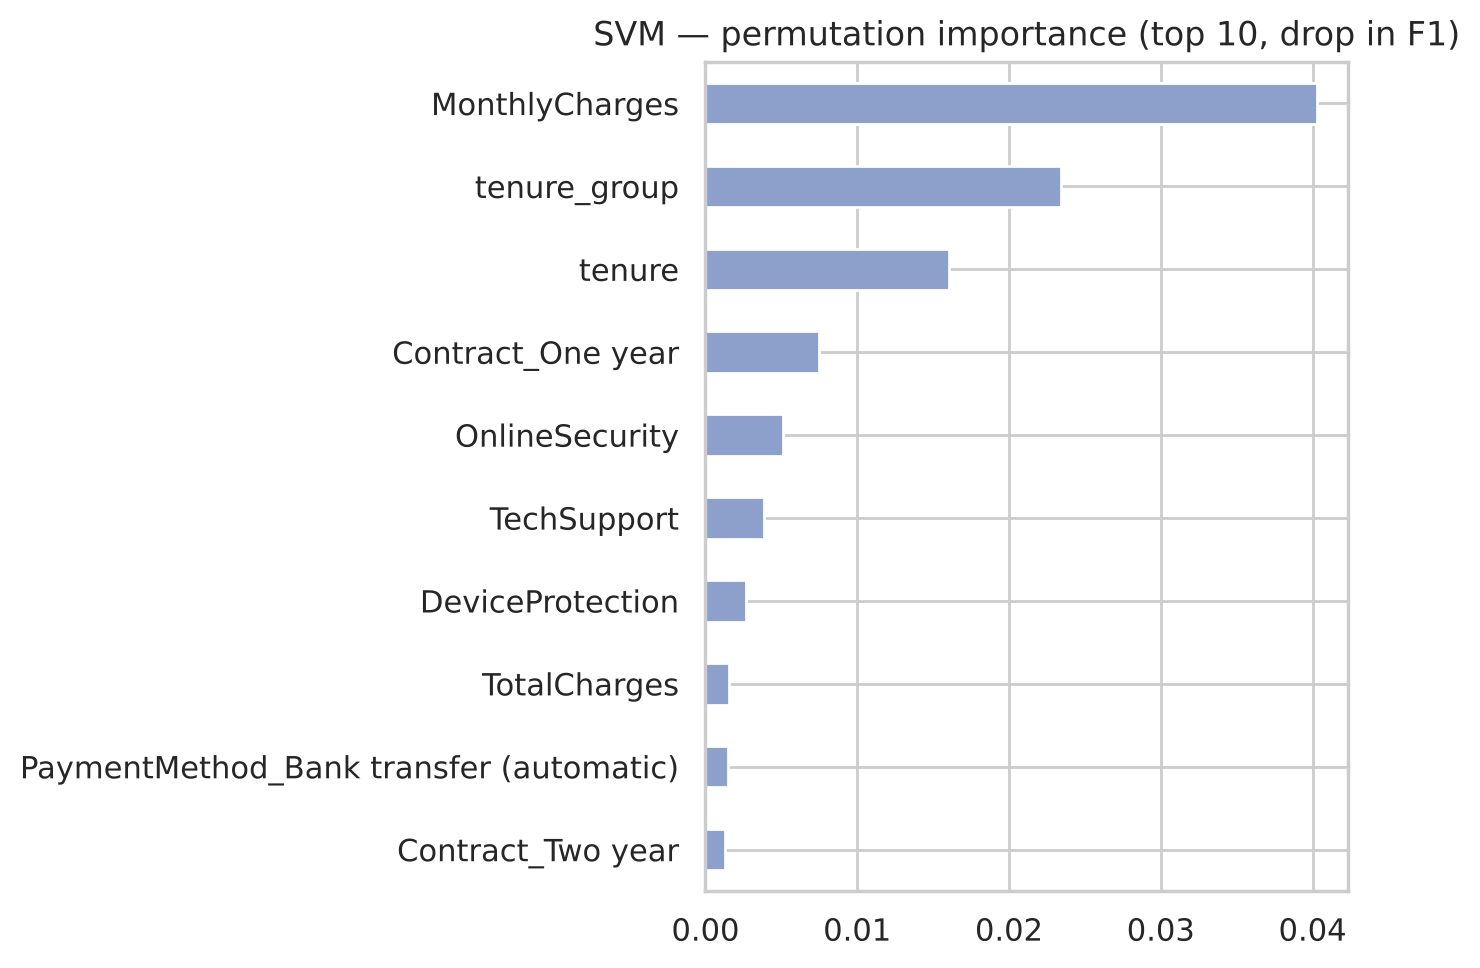

In [38]:
# Bonus: permutation importance for the SVM (black-box) on the test set
pi = permutation_importance(store["SVM"]["model"], X_test, y_test, scoring="f1", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 5)); pi_s.plot(kind="barh", ax=ax, color=sns.color_palette("Set2")[2])
ax.set_title("SVM — permutation importance (top 10, drop in F1)")
savefig("24_svm_permutation_importance")

# 🚀 Step 8: Pipeline, Deployment

## 8.1 Save the final pipeline
The pipeline takes **raw customer columns** (exactly like the CSV) → feature engineering (`churn_features.engineer`) → `StandardScaler` → (SMOTE during `fit` only) → model. So the retention team can pass raw records straight to `predict_proba`.

In [39]:
X_train_pl = df.loc[X_train_raw.index].drop(columns="Churn")        # raw train rows
X_test_pl  = df.loc[X_test_raw.index].drop(columns="Churn")         # raw test rows

use_smote = deploy_name in ("KNN", "Naive Bayes", "SVM")            # same data strategy that the model had in the notebook
steps = [("features", FunctionTransformer(cf.engineer, kw_args={"totalcharges_median": float(median_tc)})),
         ("scale", ColumnTransformer([("num", StandardScaler(), cf.NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas"))]
if use_smote:
    steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
steps.append(("model", build(deploy_name, balanced=not use_smote)))   # DT -> class_weight='balanced', others -> SMOTE
pipeline = ImbPipeline(steps).fit(X_train_pl, y_train)

pl_pred = pipeline.predict(X_test_pl); pl_proba = pipeline.predict_proba(X_test_pl)[:, 1]
print(f"Pipeline on raw test data -> Recall: {recall_score(y_test, pl_pred):.4f} | Precision: {precision_score(y_test, pl_pred):.4f} | F1: {f1_score(y_test, pl_pred):.4f} | AUC: {roc_auc_score(y_test, pl_proba):.4f}")

joblib.dump(pipeline, "churn_model.pkl")
print("Saved churn_model.pkl (%.1f KB)" % (os.path.getsize("churn_model.pkl")/1024))

Pipeline on raw test data -> Recall: 0.7834 | Precision: 0.5140 | F1: 0.6208 | AUC: 0.8162
Saved churn_model.pkl (8.1 KB)


**Test:** load the pickle in a fresh object and predict churn probability for 5 sample customers.

In [40]:
loaded = joblib.load("churn_model.pkl")
samples = df.drop(columns="Churn").sample(5, random_state=7)
proba = loaded.predict_proba(samples)[:, 1]
out = samples[["customerID", "tenure", "Contract", "MonthlyCharges"]].copy()
out["churn_probability"] = proba.round(3)
out["predicted_label"] = np.where(proba >= 0.5, "Churn", "No Churn")
out["actual"] = df.loc[samples.index, "Churn"].values
out

,customerID,tenure,Contract,MonthlyCharges,churn_probability,predicted_label,actual
6632,9259-PACGQ,34,Month-to-month,62.65,0.384,No Churn,Yes
3801,5914-DVBWJ,18,Month-to-month,85.45,0.669,Churn,Yes
901,9734-YWGEX,9,Month-to-month,98.30,0.871,Churn,Yes
1487,5035-PGZXH,56,One year,106.80,0.432,No Churn,No
1457,6362-QHAFM,42,One year,108.30,0.432,No Churn,No


## 8.2 GitHub submission
Repository files: `CustomerChurn_SupervisedLearning.ipynb`, `churn_model.pkl`, `churn_features.py`, `summary_report.md`, `requirements.txt`, `README.md`, `images/` (screenshots), dataset CSV. See `README.md` for push commands.